In [130]:
import pandas as pd
import numpy as np
from scipy.sparse import hstack, csr_matrix

from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.dummy import DummyClassifier

from sklearn.feature_selection import f_classif
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, PowerTransformer, KBinsDiscretizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedGroupKFold, PredefinedSplit
from sklearn.metrics import classification_report, f1_score, accuracy_score, silhouette_score


In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [3]:
df = pd.read_csv(Path("/mnt/data/datasets/spotify_tracks/tracks.csv"))

## 1.1 Exploratory Data Analysis

### 1.1.1 Dataset Overview

In [4]:
df.head()

,Unnamed: 0,track_name,track_id,album_name,album_id,album_image,album_release_date,album_release_date_precision,artist_name,artist_id,popularity,duration_ms,explicit,preview_url,genre,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,database_shard_id,duration_seconds,duration_minutes
0,0,"Divenire: No. 9, Fly - Intouchables",5u5scm02d5wN6nWFKuqEUK,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,2,265653,False,https://p.scdn.co/mp3-preview/81f71ca4ea95503e...,ambient,0.990,0.184,0.03270,0.877,1,0.0996,-28.184,0,0.0366,168.133,3,0.0351,0,265.653,4.427550
1,1,Spiegel im Spiegel - Heaven,1wV4SNFEXWawsyjBCGwkiw,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,0,349120,False,https://p.scdn.co/mp3-preview/040ea9c848708316...,ambient,0.985,0.250,0.01480,0.971,5,0.0669,-30.646,1,0.0375,136.864,5,0.0394,0,349.120,5.818667
2,2,Truman Sleeps - The Trumanshow,4gYub3T80gNfU9F4Df98AR,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,1,128039,False,https://p.scdn.co/mp3-preview/e9a7cd955c89d480...,ambient,0.993,0.269,0.02110,0.883,5,0.1390,-24.620,0,0.0395,69.487,4,0.0411,0,128.039,2.133983
3,3,The Heart Askes Pleasure First - The Piano,6sXRgSAQsySTM7kH1pM07Y,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,0,190960,False,https://p.scdn.co/mp3-preview/9a33da62792f8277...,ambient,0.995,0.230,0.13800,0.885,4,0.1010,-19.591,0,0.0371,165.197,3,0.1710,0,190.960,3.182667
4,4,3 Gymnopédies: I. Lent et douloureux,7Eytd0e0mNFiSWIE132H76,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,4,338933,False,https://p.scdn.co/mp3-preview/d31979ca20bbd759...,ambient,0.995,0.611,0.00162,0.967,7,0.0817,-37.782,1,0.2860,134.237,3,0.5080,0,338.933,5.648883


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2112746 entries, 0 to 2112745
Data columns (total 30 columns):
 #   Column                        Dtype  
---  ------                        -----  
 0   Unnamed: 0                    int64  
 1   track_name                    str    
 2   track_id                      str    
 3   album_name                    str    
 4   album_id                      str    
 5   album_image                   str    
 6   album_release_date            str    
 7   album_release_date_precision  str    
 8   artist_name                   str    
 9   artist_id                     str    
 10  popularity                    int64  
 11  duration_ms                   int64  
 12  explicit                      bool   
 13  preview_url                   str    
 14  genre                         str    
 15  acousticness                  float64
 16  danceability                  float64
 17  energy                        float64
 18  instrumentalness              flo

### 1.1.2 Dataset Quality

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.isnull().sum()

Unnamed: 0                           0
track_name                           6
track_id                             0
album_name                           6
album_id                             0
album_image                        491
album_release_date                   0
album_release_date_precision         0
artist_name                         17
artist_id                            0
popularity                           0
duration_ms                          0
explicit                             0
preview_url                     325237
genre                                0
acousticness                         0
danceability                         0
energy                               0
instrumentalness                     0
key                                  0
liveness                             0
loudness                             0
mode                                 0
speechiness                          0
tempo                                0
time_signature           

In [4]:
df = df.drop(columns=['Unnamed: 0', 'database_shard_id', 'preview_url', 'album_image', 'album_release_date', 'album_release_date_precision', 'duration_ms', 'duration_minutes'])
df = df.dropna()

In [5]:
df["explicit"] = df["explicit"].astype(int)

### 1.1.3 Feature Relationship and Distribution

In [21]:
df.describe()

,popularity,explicit,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,duration_seconds
count,2.112720e+06,2.112720e+06,2.112720e+06,2.112720e+06,2.112720e+06,2.112720e+06,2.112720e+06,2.112720e+06,2.112720e+06,2.112720e+06,2.112720e+06,2.112720e+06,2.112720e+06,2.112720e+06,2.112720e+06
mean,1.377669e+01,4.922896e-02,3.921951e-01,5.285403e-01,5.833899e-01,2.188440e-01,5.248907e+00,2.245107e-01,-1.025282e+01,6.620721e-01,8.522024e-02,1.202606e+02,3.873687e+00,4.874551e-01,2.494315e+02
std,1.463679e+01,2.163458e-01,3.669644e-01,1.797388e-01,2.759466e-01,3.469520e-01,3.532854e+00,2.025184e-01,5.799929e+00,4.730039e-01,1.185059e-01,2.977370e+01,4.701903e-01,2.726161e-01,1.453008e+02
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.970000e-05,0.000000e+00,0.000000e+00,2.960000e-03,-5.810000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.860000e-01
25%,1.000000e+00,0.000000e+00,2.210000e-02,4.040000e-01,3.700000e-01,1.180000e-06,2.000000e+00,9.770000e-02,-1.290100e+01,0.000000e+00,3.570000e-02,9.711000e+01,4.000000e+00,2.560000e-01,1.795000e+02
50%,9.000000e+00,0.000000e+00,2.890000e-01,5.390000e-01,6.130000e-01,8.260000e-04,5.000000e+00,1.370000e-01,-8.900000e+00,1.000000e+00,4.720000e-02,1.199840e+02,4.000000e+00,4.840000e-01,2.268815e+02
75%,2.200000e+01,0.000000e+00,7.600000e-01,6.630000e-01,8.260000e-01,4.060000e-01,8.000000e+00,2.910000e-01,-6.117000e+00,1.000000e+00,7.850000e-02,1.385590e+02,4.000000e+00,7.150000e-01,2.878800e+02
max,1.000000e+02,1.000000e+00,9.960000e-01,9.950000e-01,1.000000e+00,1.000000e+00,1.100000e+01,1.000000e+00,6.172000e+00,1.000000e+00,9.690000e-01,2.499930e+02,5.000000e+00,1.000000e+00,7.200006e+03


In [10]:
print(df['genre'].value_counts().to_string())

genre
classical            48143
blues                45752
indian               43616
german               43002
french               40832
country              38847
british              38476
alt-rock             37065
disco                34808
brazil               34482
opera                34056
turkish              33997
pop-film             32268
dance                32059
jazz                 31340
ambient              30898
gospel               30422
latin                30368
spanish              30298
folk                 29167
funk                 28505
guitar               27087
bluegrass            27073
k-pop                26456
j-pop                26114
swedish              25838
dub                  25670
acoustic             25669
children             25597
new-age              25164
mpb                  25108
anime                24623
black-metal          23511
dancehall            23477
forro                23266
cantopop             23036
death-metal          2

In [6]:
df_numeric = df.select_dtypes(include='number')

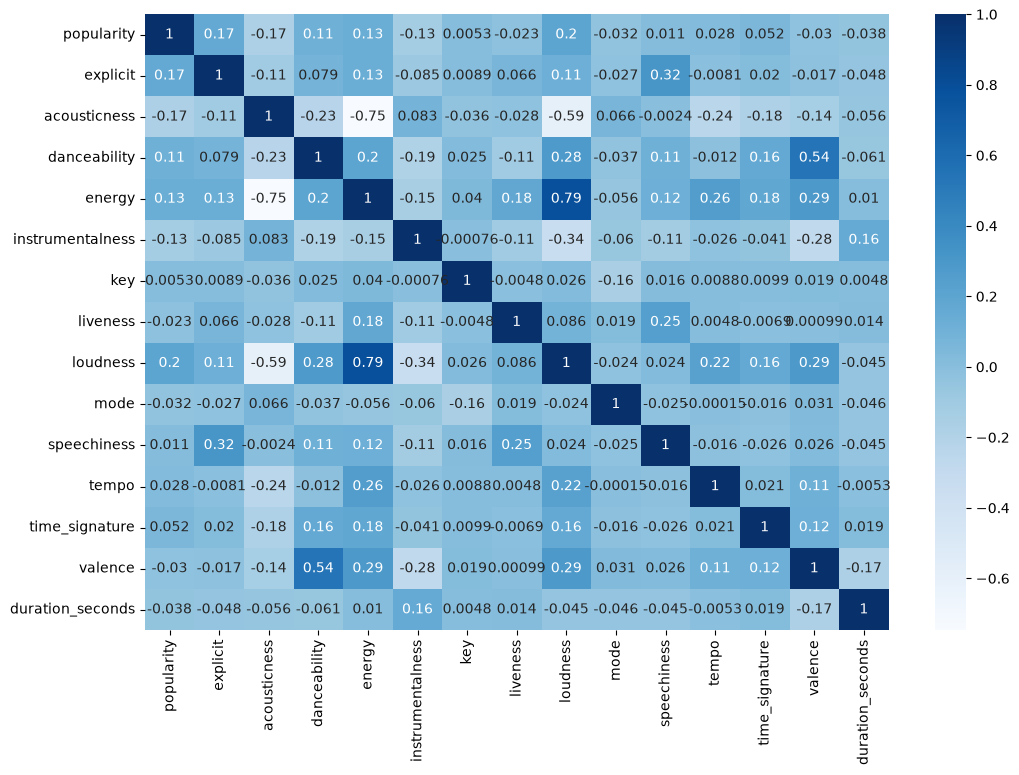

In [32]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df_numeric.corr(),
    annot=True,
    cmap='Blues'
)

plt.show()

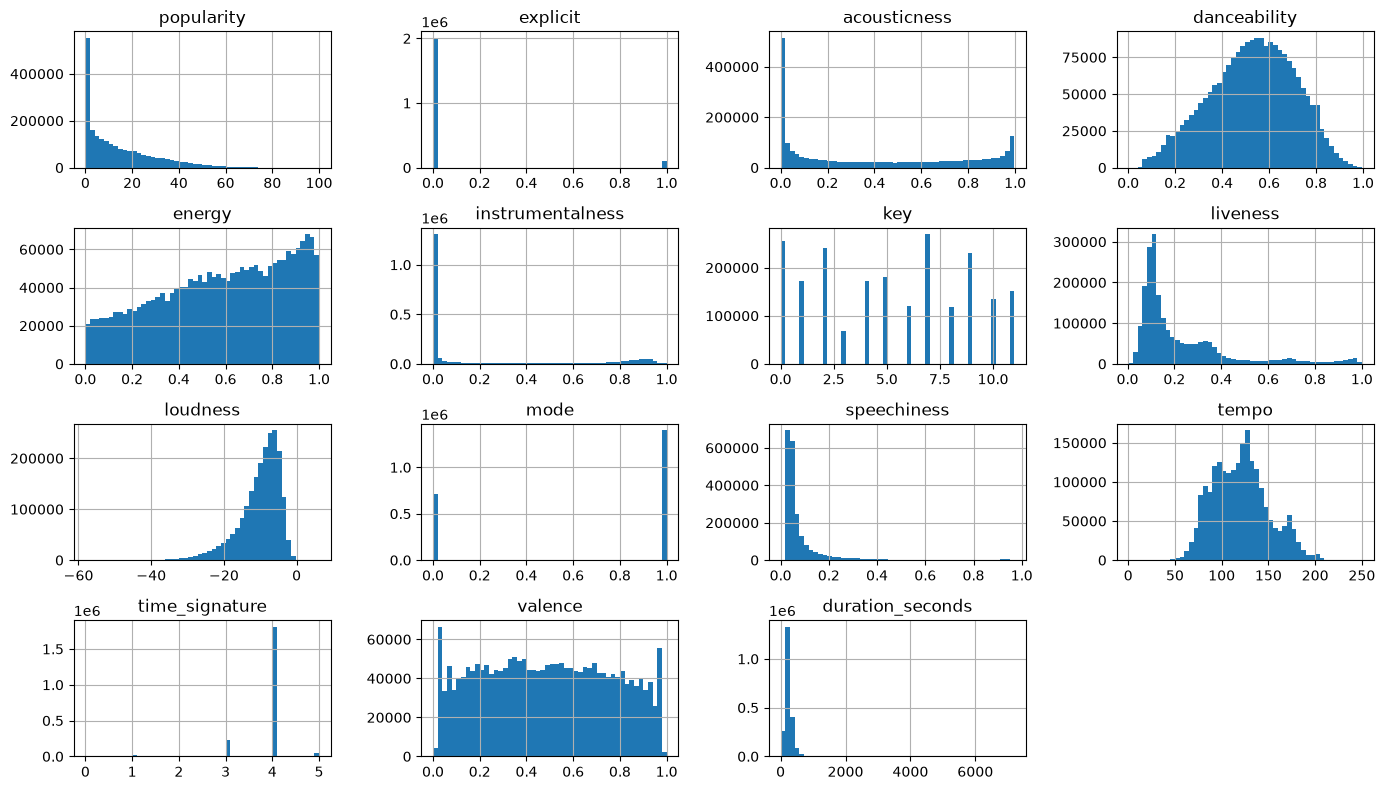

In [33]:
df_numeric.hist(bins=50, figsize=(14, 8))

plt.tight_layout()
plt.show()

In [ ]:
pd.plotting.scatter_matrix(df_numeric, figsize = (12,12))

KeyboardInterrupt: 

Error in callback <function _draw_all_if_interactive at 0x7b1dd05e9bc0> (for post_execute), with arguments args (),kwargs {}:


KeyboardInterrupt: 

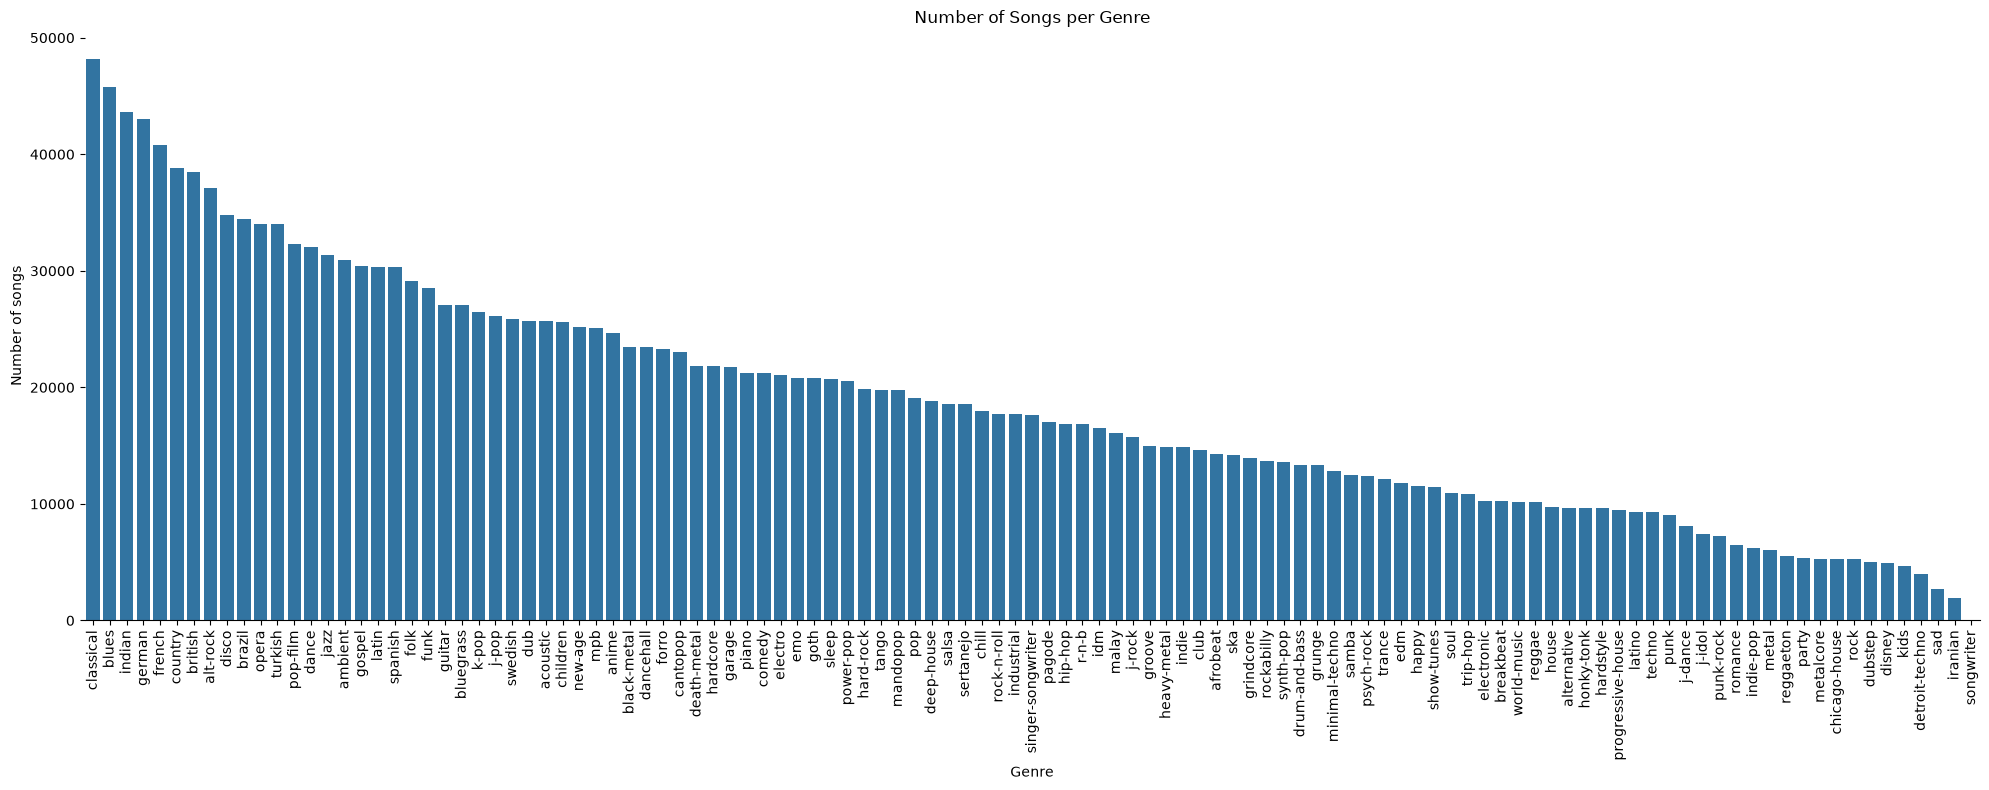

In [7]:
plt.figure(figsize=(20, 8))

genre_order = df["genre"].value_counts().index

ax = sns.countplot(
    data=df,
    x="genre",
    order=genre_order
)

plt.xticks(rotation=90)
plt.xlabel("Genre")
plt.ylabel("Number of songs")
plt.title("Number of Songs per Genre")
sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

In [25]:
print(f'Number of unique tracks: {df['track_id'].nunique()}')
print(f"Number of unique albums: {df['album_id'].nunique()}")
print(f"Number of unique artists: {df['artist_name'].nunique()}")
print(f"Number of unique genres: {df['genre'].nunique()}")

Number of unique tracks: 2112720
Number of unique albums: 464274
Number of unique artists: 77410
Number of unique genres: 113


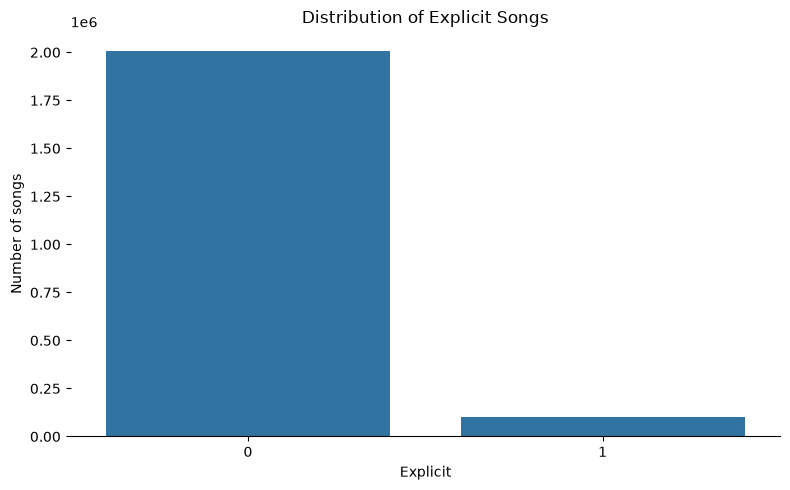

In [8]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="explicit",
    order=df["explicit"].value_counts().index
)

plt.xlabel("Explicit")
plt.ylabel("Number of songs")
plt.title("Distribution of Explicit Songs")

sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

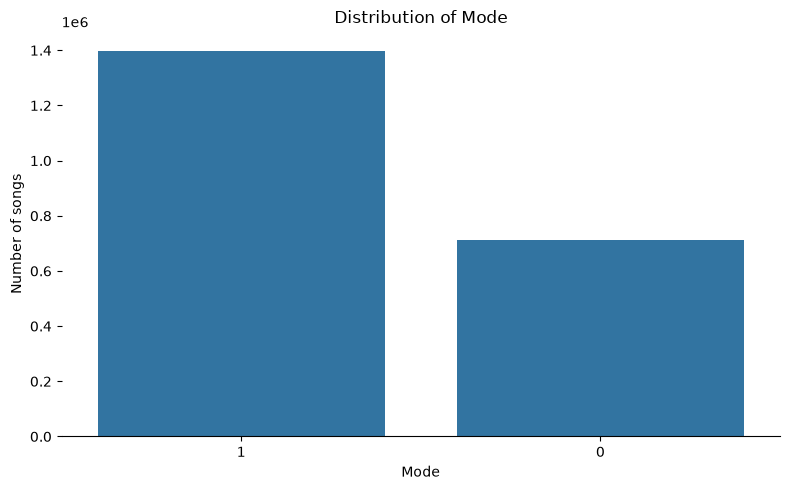

In [12]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="mode",
    order=df["mode"].value_counts().index
)

plt.xlabel("Mode")
plt.ylabel("Number of songs")
plt.title("Distribution of Mode")

sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

### 1.1.4 Feature Class Balance

The histograms above show that some continous numerical features have asymmetric distributions. Skewness describes the asymmetry of a data distribution around its mean.
This could negatively impact the performance of models that assume normally distributed data or are sensitive to the variance of input features, such as linear regression, principal component analysis (PCA), and support vector machines (SVMs).
- **Positive skewness (right-skewed):** the distribution has a longer tail towards higher values.
- **Negative skewness (left-skewed):** the distribution has a longer tail towards lower values.

Based on the histograms, the following features appear to be positively skewed:
- `duration_seconds`
- `liveness`
- `instrumentalness`
- `popularity`

The following features appear to be negatively skewed:
- `energy`
- `loudness`

The skewness of `acousticness` is less clear from the histogram alone and will be investigated further in the next step.

In [9]:
df_numeric.skew()

popularity          1.193135
explicit            4.167139
acousticness        0.372808
danceability       -0.218409
energy             -0.324793
instrumentalness    1.193576
key                -0.001299
liveness            1.960634
loudness           -1.393427
mode               -0.685289
speechiness         4.772669
tempo               0.360192
time_signature     -3.139475
valence             0.047022
duration_seconds    8.493171
dtype: float64

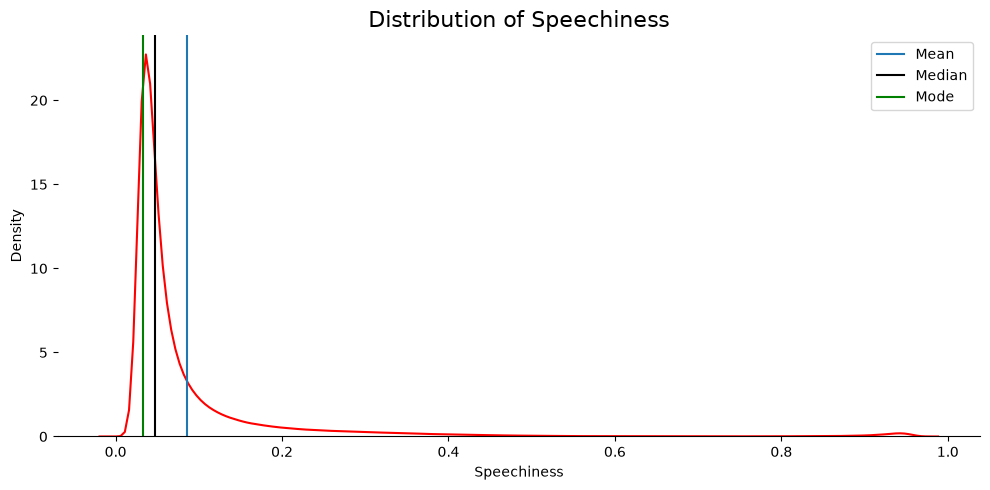

In [16]:
# Find the mean, median, mode
mean_value = df["speechiness"].mean()
median_value = df["speechiness"].median()
mode_value = df["speechiness"].mode().iloc[0]

plt.figure(figsize=(10, 5))
sns.kdeplot(x=df['speechiness'], color="red")

# Add vertical lines at the position of mean, median, mode
plt.axvline(mean_value, label="Mean")
plt.axvline(median_value, color="black", label="Median")
plt.axvline(mode_value, color="green", label="Mode")

plt.title("Distribution of Speechiness", fontsize=16)
plt.xlabel("Speechiness")
plt.ylabel("Density")
sns.despine(top=True, right=True, left=True)
plt.legend()
plt.tight_layout()
plt.show()


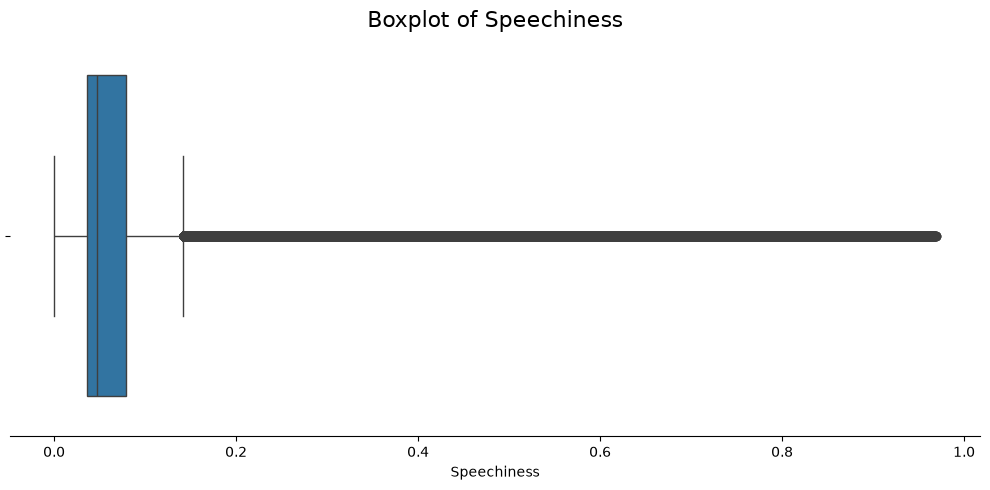

In [17]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["speechiness"])

plt.title("Boxplot of Speechiness", fontsize=16)
plt.xlabel("Speechiness")
sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

The KDE plot (*continous*) and boxplot of speechiness confirm its positive skewness of 4.77, as we saw on the histogram (*bins*). Most observations are concentrated at **lower values**, with a **long tail** extending towards higher values, on the right side of the peak.

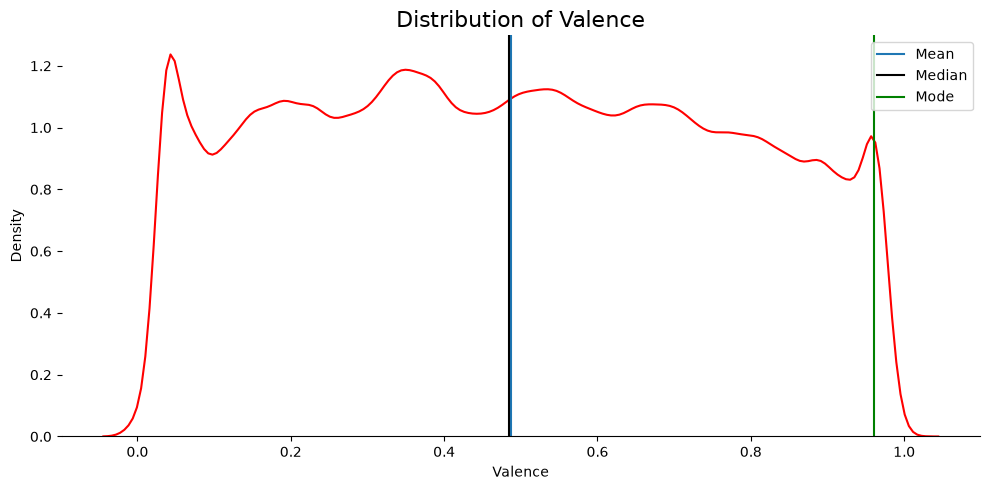

In [19]:
# Find the mean, median, mode
mean_value = df["valence"].mean()
median_value = df["valence"].median()
mode_value = df["valence"].mode().iloc[0]

plt.figure(figsize=(10, 5))
sns.kdeplot(x=df['valence'], color="red")

# Add vertical lines at the position of mean, median, mode
plt.axvline(mean_value, label="Mean")
plt.axvline(median_value, color="black", label="Median")
plt.axvline(mode_value, color="green", label="Mode")

plt.title("Distribution of Valence", fontsize=16)
plt.xlabel("Valence")
plt.ylabel("Density")
sns.despine(top=True, right=True, left=True)
plt.legend()
plt.tight_layout()
plt.show()


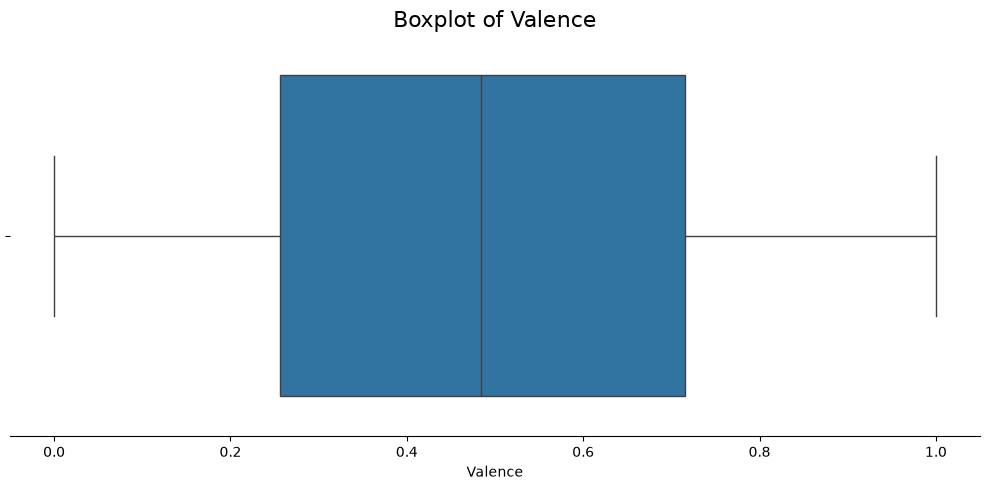

In [20]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["valence"])

plt.title("Boxplot of Valence", fontsize=16)
plt.xlabel("Valence")
sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

The KDE plot and boxplot of valence show a relatively symmetric distribution, consistent with its near-zero skewness of 0.05, as observed in the histogram. The mean and median are close together, and the distribution does not show a pronounced tail towards either lower or higher values.

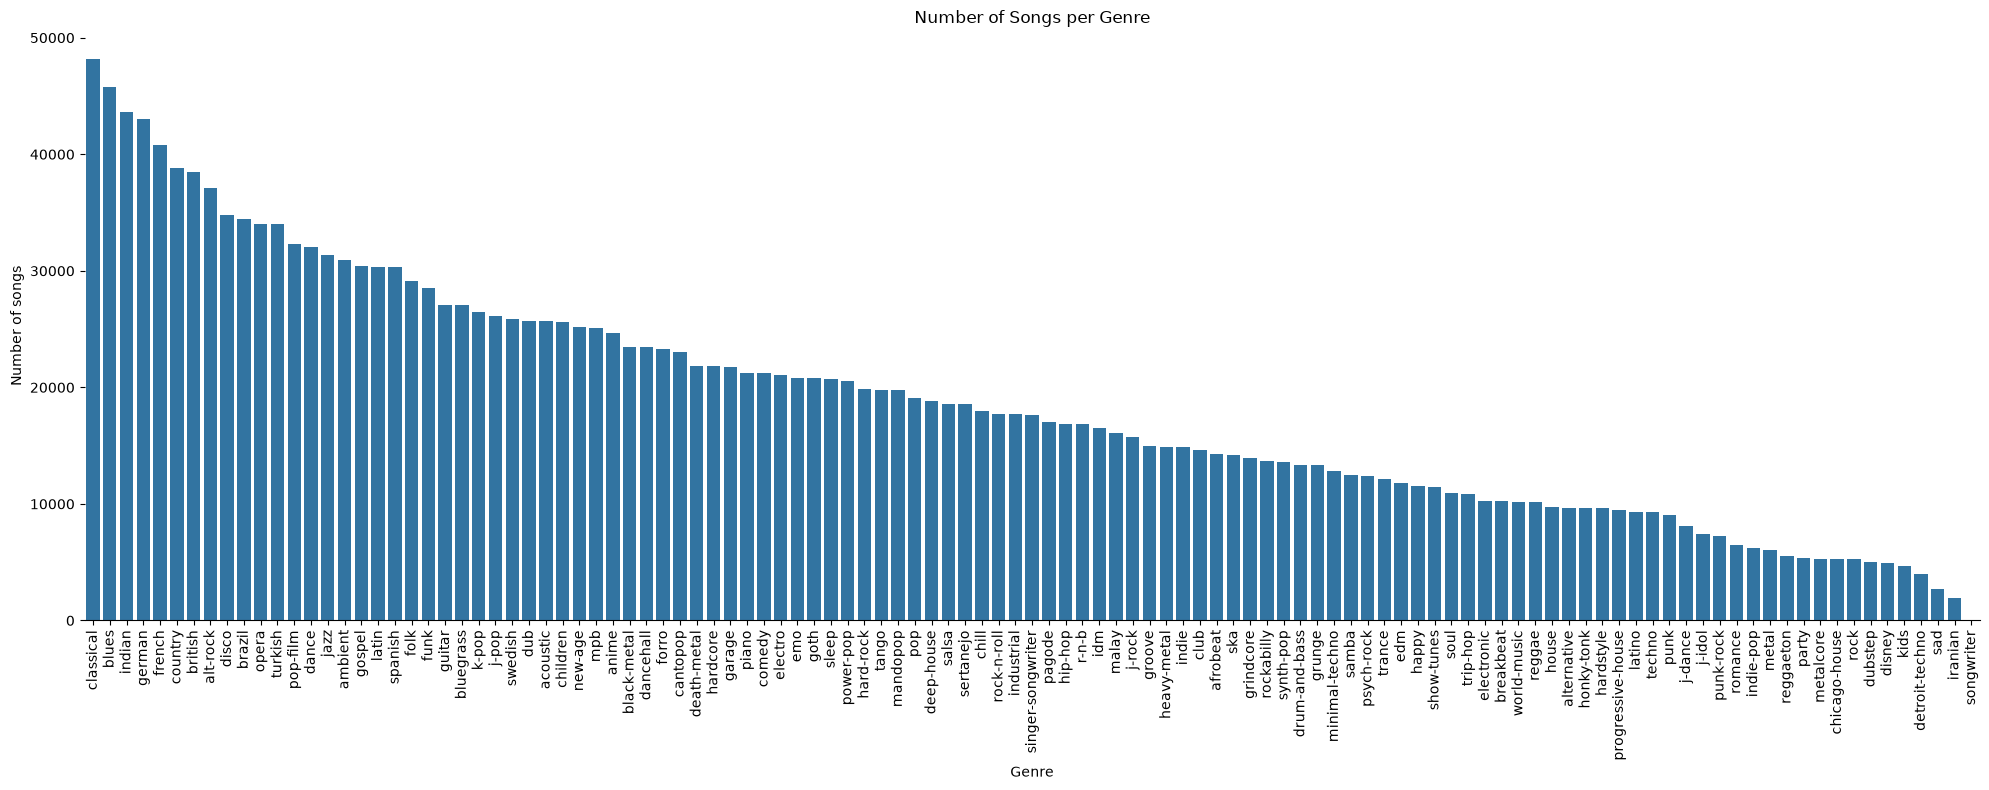

In [13]:
plt.figure(figsize=(20, 8))

genre_order = df["genre"].value_counts().index

ax = sns.countplot(
    data=df,
    x="genre",
    order=genre_order
)

plt.xticks(rotation=90)
plt.xlabel("Genre")
plt.ylabel("Number of songs")
plt.title("Number of Songs per Genre")
sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

The countplot shows the distribution of tracks across genres (113), ordered from most frequent to least frequent. The number of tracks varies considerably between genres: classical is the most represented genre, with 48,143 tracks, whereas songwriter has only 66 tracks. This indicates a substantial class imbalance, which may cause the classification model to perform better on well-represented genres than on underrepresented ones.

### 1.1.5 Correlation and Multicollinearity

In [7]:
le = LabelEncoder()

In [8]:
df['genre'] = le.fit_transform(df["genre"])

In the next step we calculate the **ANOVA F-statistic**, as our input variables are numerical and output variables are non-ordinal categorical. This informs us what features correlate highly with the label `genre`.

For more information, see [How to Choose a Feature Selection Method For Machine Learning](https://machinelearningmastery.com/feature-selection-with-real-and-categorical-data/).

In [11]:
f_statistic, _ = f_classif(df_numeric, df['genre'])

anova_df = pd.DataFrame({
    "feature": df_numeric.columns,
    "F-value": f_statistic
}).sort_values("F-value", ascending=False)

anova_df

,feature,F-value
2,acousticness,15341.381870
4,energy,12725.056429
10,speechiness,12482.180857
8,loudness,11721.134834
3,danceability,9761.926486
5,instrumentalness,9546.465465
13,valence,7156.577619
0,popularity,5811.257996
1,explicit,4485.743419
14,duration_seconds,2017.891713


The highest F-values observed are `acousticness`, `speechiness` and `energy`.

We calculate the **Variance Inflation Factor** (VIF) to detect multicollinearity between the numerical input variables. This indicates whether some features contain overlapping information, and could therefore mislead the model.

In [12]:
vif_df = pd.DataFrame({
    "feature": df_numeric.columns,
    "VIF": [
        variance_inflation_factor(df_numeric.values, i)
        for i in range(df_numeric.shape[1])
    ]
}).sort_values("VIF", ascending=False)

vif_df

,feature,VIF
4,energy,4.806935
8,loudness,3.310650
2,acousticness,2.554418
13,valence,1.739758
3,danceability,1.667658
5,instrumentalness,1.315740
10,speechiness,1.268932
1,explicit,1.162053
7,liveness,1.160771
0,popularity,1.105422


A VIF value equal to 1 indicates **no multicollinearity**, while a VIF between 1 and 5 indicates a **moderate** level of multicollinearity. A VIF greater than 5 indicates potentially **problematic** multicollinearity.

The highest VIF values were observed for `energy` and `loudness`. Both values are below the threshold of 5, indicating that there is no significant multicollinearity between the input features. Therefore, both features can remain in the dataset.

## 1.2 Data Preparation

### 1.2.1 Feature Engineering

We remove the `popularity` feature because it reflects a track's popularity rather than its intrinsic audio characteristics or textual metadata. 

Since our objective is to build a model that generalizes to unseen data, relying on popularity could be problematic, as it can change over time and may introduce biases towards more popular tracks.

However, popularity could be useful in a recommendation system for a platform such as Spotify or Deezer, where it provides additional information about listening trends and user preferences. In that context, popularity data could be regularly updated to reflect changing trends.

In [9]:
df = df.drop(columns='popularity')

In [10]:
df['duration_seconds'] = df['duration_seconds'].round().astype(int)

In [11]:
ohe_key = OneHotEncoder(sparse_output=False).set_output(transform='pandas')
ohe_time_signature = OneHotEncoder(sparse_output=False).set_output(transform='pandas')

Our dataset also consists of categorical features: `key` and `time_signature`, which we convert using one-hot encoding into numerical features. This is a better option than ordinal encoding, as it prevents models from assuming an incorrect order between categories

In [12]:
df_key = ohe_key.fit_transform(df[['key']])
df_time_signature = ohe_time_signature.fit_transform(df[['time_signature']])

In [13]:
df["album_songs"] = (
    df.groupby("album_id")["track_name"]
    .transform("count")
)

In [14]:
df["avg_album_song_duration"] = (
    df.groupby("album_id")["duration_seconds"].transform("sum")
    / df["album_songs"]
)

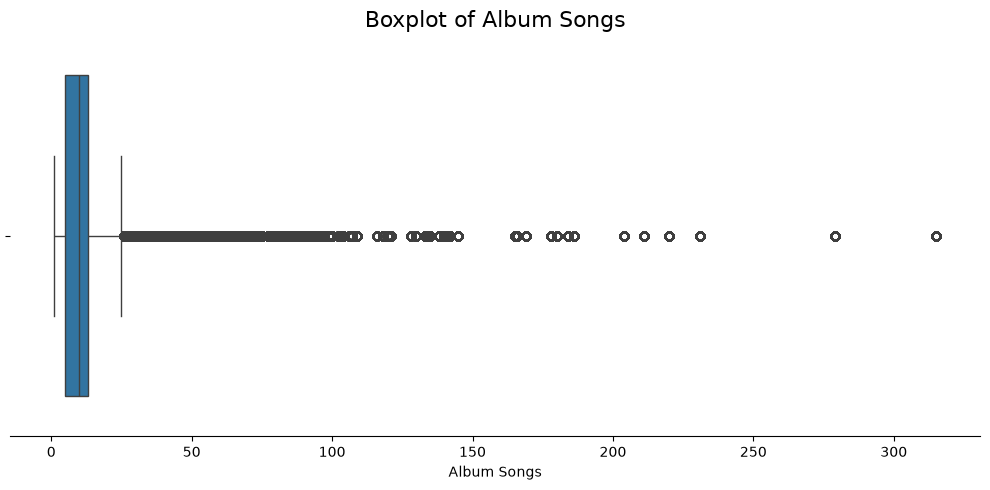

In [17]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df['album_songs'])

plt.title("Boxplot of Album Songs", fontsize=16)
plt.xlabel("Album Songs")
sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

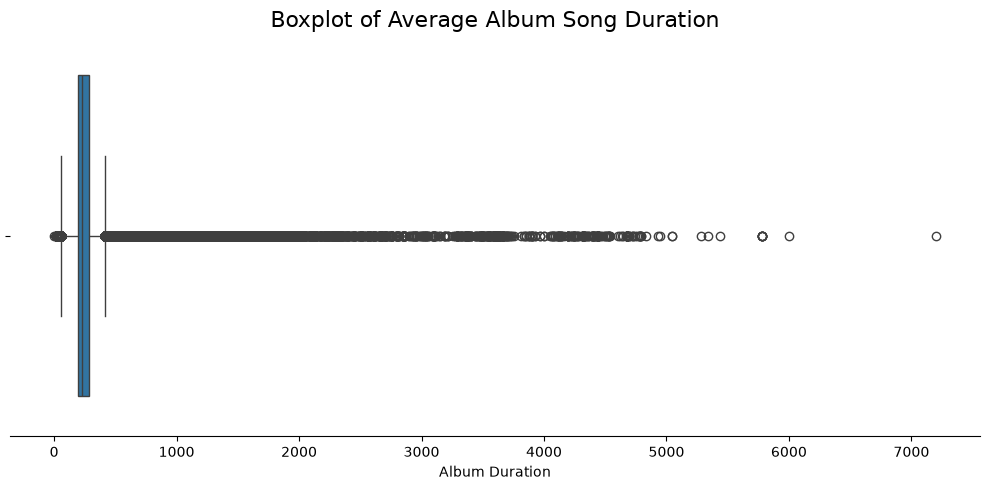

In [126]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df['avg_album_song_duration'])

plt.title("Boxplot of Average Album Song Duration", fontsize=16)
plt.xlabel("Album Duration")
sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

### 1.2.2 Feature Transformation

In [15]:
X = df.drop(columns='genre')
y = df['genre']

In [16]:
def detect_outliers(ds: pd.Series):
    Q1 = ds.quantile(0.25)
    Q3 = ds.quantile(0.75)
    IQR = Q3 - Q1

    outliers = (
        (ds < Q1 - 1.5 * IQR) |
        (ds > Q3 + 1.5 * IQR)
    )

    return outliers

We use the Interquartile Range (IQR) method to identify potential outliers in our dataset. The features `album_songs` and `album_duration` contain 121,074 (5.73%) and 105,243 (4.98%) potential outliers, respectively. We then inspect these observations to better understand their characteristics and determine whether they represent unusual but valid data points.

In [123]:
album_songs_outliers = detect_outliers(X['album_songs'])
print(f"{album_songs_outliers.sum():,} - potential outliers ({album_songs_outliers.mean():.2%})")

121,074 - potential outliers (5.73%)


In [129]:
avg_album_song_duration_outliers = detect_outliers(X['avg_album_song_duration'])
print(f"{avg_album_song_duration_outliers.sum():,} - potential outliers ({avg_album_song_duration_outliers.mean():.2%})")

109,209 - potential outliers (5.17%)


In [137]:
outlier_songs = df.loc[
    album_songs_outliers,
    ["track_name", "album_name", "artist_name", "album_songs", "genre"]
].sort_values("album_songs", ascending=False)

display(outlier_songs.head(10))
display(outlier_songs.tail(10))

,track_name,album_name,artist_name,album_songs,genre
44791,"Heinichen: Kleines harmonisches Labyrinth, BWV...",Bach: Complete Organ Works (Analogue Version -...,Johann David Heinichen,315,39
44774,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,Nicolaus Vetter,315,39
44775,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,Nicolaus Vetter,315,39
44776,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,Nicolaus Vetter,315,39
44778,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,Nicolaus Vetter,315,39
44779,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,Nicolaus Vetter,315,39
44780,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,Nicolaus Vetter,315,39
44781,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,Nicolaus Vetter,315,39
44782,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,Nicolaus Vetter,315,39
44784,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,Nicolaus Vetter,315,39


,track_name,album_name,artist_name,album_songs,genre
934056,"How Long, How Long Blues",Atomic Boogie,Big Joe Turner,26,92
934055,Rock Of Gibraltar Blues,Atomic Boogie,Big Joe Turner,26,92
934054,Howling Winds,Atomic Boogie,Big Joe Turner,26,92
934053,Whistle Stop Blues,Atomic Boogie,Big Joe Turner,26,92
934052,It's A Low Down Dirty Shame,Atomic Boogie,Big Joe Turner,26,92
2111869,Ağla Ağla - Live,Söz & Müzik: Tan Taşçı (Live),Tan Taşçı,26,111
2111868,Ziyan & Doğum Günü - Live,Söz & Müzik: Tan Taşçı (Live),Tan Taşçı,26,111
2111867,Yalvarırım - Live,Söz & Müzik: Tan Taşçı (Live),Tan Taşçı,26,111
140341,Born In a Trunk - Instrumental,"Very 'Eavy, Very 'Umble (Expanded Version)",Uriah Heep,26,47
140304,Dreammare - Alternative Version,"Very 'Eavy, Very 'Umble (Expanded Version)",Uriah Heep,26,47


In [138]:
le.inverse_transform([39, 92, 111, 47])

array(['german', 'rockabilly', 'turkish', 'hard-rock'], dtype=object)

In [135]:
outlier_songs = df.loc[
    album_songs_outliers,
    ["track_name", "album_name", "artist_name", "avg_album_song_duration", "genre"]
].sort_values("avg_album_song_duration", ascending=False)

display(outlier_songs.head(10))
display(outlier_songs.tail(10))

,track_name,album_name,artist_name,avg_album_song_duration,genre
1550492,Suspended Animation With Ocean (Lambda Binaura...,"Binaural Beats, Isochronic Tones Brainwave Ent...",Binaural Beats Isochronic Tones Lab,701.793103,101
1549656,741 Hz Awakening Intuition,"Binaural Beats, Isochronic Tones Brainwave Ent...",Binaural Beats Isochronic Tones Lab,701.793103,101
1549831,Music for Astral Projection (Beta Binaural Beats),"Binaural Beats, Isochronic Tones Brainwave Ent...",Binaural Beats Isochronic Tones Lab,701.793103,101
1550426,Healing Yoga Music (Epsilon Binaural Beats),"Binaural Beats, Isochronic Tones Brainwave Ent...",Binaural Beats Isochronic Tones Lab,701.793103,101
1550371,Paradigm Shift (Epsilon Binaural Beats),"Binaural Beats, Isochronic Tones Brainwave Ent...",Binaural Beats Isochronic Tones Lab,701.793103,101
1550489,Sports Endurance Booster (Gamma Isochronic Tones),"Binaural Beats, Isochronic Tones Brainwave Ent...",Binaural Beats Isochronic Tones Lab,701.793103,101
1549813,639 Hz Connecting / Relationships,"Binaural Beats, Isochronic Tones Brainwave Ent...",Binaural Beats Isochronic Tones Lab,701.793103,101
1549650,528 Hz Transformation and Miracles (Dna Repair),"Binaural Beats, Isochronic Tones Brainwave Ent...",Binaural Beats Isochronic Tones Lab,701.793103,101
1549873,Melitonin Production Increase (Delta Isochroni...,"Binaural Beats, Isochronic Tones Brainwave Ent...",Binaural Beats Isochronic Tones Lab,701.793103,101
1550308,Time Traveling (Gamma Isochronic Tones),"Binaural Beats, Isochronic Tones Brainwave Ent...",Binaural Beats Isochronic Tones Lab,701.793103,101


,track_name,album_name,artist_name,avg_album_song_duration,genre
1512395,Woman,Ogoola Karuta English Classics 1-50,Myrra Malmberg,29.5,26
1512399,The Triumph of Life,Ogoola Karuta English Classics 1-50,Myrra Malmberg,29.5,26
1512471,Lament for the Makers,Ogoola Karuta English Classics 1-50,Myrra Malmberg,29.5,26
1512403,They Flee from Me,Ogoola Karuta English Classics 1-50,Myrra Malmberg,29.5,26
1512397,The Lady's Dressing Room,Ogoola Karuta English Classics 1-50,Myrra Malmberg,29.5,26
1512394,"To the Virgins, To Make Much of Time",Ogoola Karuta English Classics 1-50,Myrra Malmberg,29.5,26
1512387,The Passionate Shepherd to His Love,Ogoola Karuta English Classics 1-50,Myrra Malmberg,29.5,26
1512388,Brahma,Ogoola Karuta English Classics 1-50,Myrra Malmberg,29.5,26
1512390,Her Triumph,Ogoola Karuta English Classics 1-50,Myrra Malmberg,29.5,26
1512393,Jubilate Agno from Fragment B2,Ogoola Karuta English Classics 1-50,Myrra Malmberg,29.5,26


In [136]:
le.inverse_transform([26, 101])

array(['disney', 'sleep'], dtype=object)

### 1.2.3 Data Splitting and Stratification

We split our dataset into three subsets: 80% for training, 10% for validation, and 10% for testing. To achieve this while minimizing data leakage, we used StratifiedGroupKFold, with album_id as the grouping variable and genre as the stratification target.

**Grouping by album** ensures that all tracks belonging to the same album assigned to the same subset. This prevents tracks from the same album from appearing in both the training and evaluation sets, reducing the risk of data leakage, and so overly optimistic performance estimates caused by similarities between tracks from the same album.

**Stratification** by genre helps preserve the genre distribution across the subsets, ensuring each subset remains reasonably representative of the overall dataset.

In [16]:
groups = X['album_id']

In [17]:
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [18]:
train_idx, remaining_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
y_train = y.iloc[train_idx]

X_remaining = X.iloc[remaining_idx]
y_remaining = y.iloc[remaining_idx]

In [19]:
groups_remaining = groups.iloc[remaining_idx]

In [20]:
splitter_remaining = StratifiedGroupKFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

In [21]:
validation_idx, test_idx = next(
    splitter_remaining.split(
        X_remaining,
        y_remaining,
        groups=groups_remaining
    )
)

X_validation = X_remaining.iloc[validation_idx]
y_validation = y_remaining.iloc[validation_idx]

X_test = X_remaining.iloc[test_idx]
y_test = y_remaining.iloc[test_idx]

In [25]:
print(f"Train:      {len(X_train):,} ({len(X_train) / len(X):.1%})")
print(f"Validation: {len(X_validation):,} ({len(X_validation) / len(X):.1%})")
print(f"Test:       {len(X_test):,} ({len(X_test) / len(X):.1%})")

Train:      1,690,176 (80.0%)
Validation: 211,272 (10.0%)
Test:       211,272 (10.0%)


### 1.2.4 Feature Extraction using TF-IDF

We also used the `track_name` and `album_name` features, as their text may contain useful information for predicting a track's genre. We applied TF-IDF to the combined text ({track_name} {album_name}) to represent words based on their frequency within a document and their relative rarity across the dataset. This allows the model to identify textual patterns that may be associated with particular genres.

In [ ]:
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(token_pattern=r"(?u)\b[^\W\d_]+\b")),
    ("clf", MultinomialNB())
])

In [56]:
parameters = {
    "tfidf__ngram_range": [(1, 1), (1, 2), (1,3)],
    "tfidf__max_features": [1000],
    "tfidf__min_df": [2, 3, 5, 8, 10, 15],
    "tfidf__max_df": [0.5, 0.75],
}

In [ ]:
#X_tuning = np.concatenate([
#    X_train["track_name"].astype(str).to_numpy(),
#    X_validation["track_name"].astype(str).to_numpy()
#])

#X_tuning = np.concatenate([
#    X_train["album_name"].astype(str).to_numpy(),
#    X_validation["album_name"].astype(str).to_numpy()
#])

In [ ]:
X_tuning = np.concatenate([
    X_train[["track_name", "album_name"]].agg(" ".join, axis=1).to_numpy(),
    X_validation[["track_name", "album_name"]].agg(" ".join, axis=1).to_numpy()
])

y_tuning = np.concatenate([
    y_train.to_numpy(),
    y_validation.to_numpy()
])

# -1 = training sample, 0 = validation sample
test_fold = np.concatenate([
    np.full(len(X_train), -1),
    np.zeros(len(X_validation), dtype=int)
])

validation_split = PredefinedSplit(test_fold)

We experimented with different TF-IDF hyperparameters, including **ngram_range**, **min_df**, and **max_df**, to find a suitable configuration. The ngram_range parameter determines whether individual words or combinations of consecutive words are considered, while min_df and max_df filter out terms that occur in too few or too many documents, respectively.

In [68]:
grid_search = GridSearchCV(
    pipeline,
    parameters,
    cv=validation_split,
    scoring="f1_macro",
    verbose=2,
    n_jobs=10
)

In [69]:
grid_search.fit(X_tuning, y_tuning)

Fitting 1 folds for each of 36 candidates, totalling 36 fits


[CV] END tfidf__max_df=0.5, tfidf__max_features=1000, tfidf__min_df=2, tfidf__ngram_range=(1, 1); total time=   6.1s
[CV] END tfidf__max_df=0.5, tfidf__max_features=1000, tfidf__min_df=3, tfidf__ngram_range=(1, 1); total time=   5.8s
[CV] END tfidf__max_df=0.5, tfidf__max_features=1000, tfidf__min_df=5, tfidf__ngram_range=(1, 1); total time=   6.1s
[CV] END tfidf__max_df=0.5, tfidf__max_features=1000, tfidf__min_df=8, tfidf__ngram_range=(1, 1); total time=   7.2s
[CV] END tfidf__max_df=0.5, tfidf__max_features=1000, tfidf__min_df=2, tfidf__ngram_range=(1, 2); total time=  10.4s
[CV] END tfidf__max_df=0.5, tfidf__max_features=1000, tfidf__min_df=3, tfidf__ngram_range=(1, 2); total time=  10.9s
[CV] END tfidf__max_df=0.5, tfidf__max_features=1000, tfidf__min_df=5, tfidf__ngram_range=(1, 2); total time=  12.3s
[CV] END tfidf__max_df=0.5, tfidf__max_features=1000, tfidf__min_df=2, tfidf__ngram_range=(1, 3); total time=  14.4s
[CV] END tfidf__max_df=0.5, tfidf__max_features=1000, tfidf__min

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...inomialNB())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'tfidf__max_df': [0.5, 0.75], 'tfidf__max_features': [1000], 'tfidf__min_df': [2, 3, ...], 'tfidf__ngram_range': [(1, ...), (1, ...), ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",10
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","PredefinedSpl...e=(1901448,)))"
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about mu

In [70]:
print("Best parameters:", grid_search.best_params_)
print("Best validation macro-F1:", grid_search.best_score_)

Best parameters: {'tfidf__max_df': 0.5, 'tfidf__max_features': 1000, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)}
Best validation macro-F1: 0.10956156524627252


Using a **vocabulary** size of 1,000 terms, we obtained the following macro-F1 scores:

- track_name only: 0.075

- album_name only: 0.113

- track_name and album_name combined: 0.121

Combining both text features achieved the best result, suggesting that track titles and album titles provide complementary information for genre classification. However, the improvement was relatively modest.

In [111]:
best_model = grid_search.best_estimator_

tfidf = best_model.named_steps["tfidf"]

vocabulary = tfidf.get_feature_names_out()

print(vocabulary[:100])

['a' 'about' 'acoustic' 'act' 'acústico' 'adagio' 'after' 'again' 'age'
 'ah' 'ain' 'air' 'al' 'album' 'alive' 'all' 'allegretto' 'allegro' 'alma'
 'alone' 'along' 'alright' 'alternate' 'always' 'am' 'amar' 'america'
 'american' 'amor' 'amour' 'an' 'and' 'andante' 'angel' 'angels'
 'anniversary' 'anos' 'another' 'anthem' 'anthology' 'ao' 'are' 'arena'
 'aria' 'arms' 'around' 'arr' 'art' 'as' 'asot' 'at' 'au' 'auf' 'aus'
 'away' 'años' 'b' 'baby' 'bach' 'back' 'bad' 'ballet' 'band' 'bang' 'bar'
 'bass' 'battle' 'be' 'beach' 'beat' 'beats' 'beautiful' 'beauty' 'been'
 'beethoven' 'before' 'behind' 'believe' 'bells' 'ben' 'best' 'better'
 'between' 'beyond' 'big' 'bir' 'bird' 'bizet' 'black' 'blind' 'blood'
 'blue' 'bluegrass' 'blues' 'body' 'bonus' 'boogie' 'book' 'boom' 'bop']


### 1.2.5 Feature Preprocessing

As discussed in [Feature Distribution and Class Imbalance](#114-feature-distribution-and-class-imbalance), some numerical features exhibit skewness.

To address this, we use the **Yeo–Johnson transformation**, a power transformation that can reduce skewness in numerical features. We chose this method because our dataset contains both positive and negative values, and Yeo–Johnson can also handle zero values. Unlike the Box–Cox transformation, which requires strictly positive values, Yeo–Johnson can be applied to a wider range of numerical data.

We enable standardization as part of the transformation so that the resulting features have a mean of approximately zero and a standard deviation of approximately one. The transformation is fitted on the training data only to prevent data leakage.

For more information, see [Skewness Be Gone: Transformative Tricks for Data Scientists](https://machinelearningmastery.com/skewness-be-gone-transformative-tricks-for-data-scientists/).

In [71]:
df.skew(numeric_only=True)

explicit            4.167158
genre               0.268191
acousticness        0.372811
danceability       -0.218410
energy             -0.324785
instrumentalness    1.193545
key                -0.001304
liveness            1.960641
loudness           -1.393415
mode               -0.685279
speechiness         4.772682
tempo               0.360188
time_signature     -3.139468
valence             0.047027
duration_seconds    8.492853
album_songs         8.132853
dtype: float64

In [22]:
continuous_features = [
    'acousticness',
    'danceability',
    'energy',
    'instrumentalness',
    'liveness',
    'loudness',
    'speechiness',
    'tempo',
    'valence',
    'duration_seconds'
]

categorical_features = [
    "key",
    "time_signature",
]

binary_features = [
    'mode',
    'explicit'
]

skewed_features = [
    'instrumentalness',
    'liveness',
    'loudness',
    'speechiness',
    'duration_seconds',
    'album_songs'
]

In [23]:
non_skewed_features = [
    feature for feature in continuous_features
    if feature not in skewed_features
]

In [71]:
ss = StandardScaler().set_output(transform='pandas')
pt = PowerTransformer(method='yeo-johnson', standardize=True).set_output(transform='pandas')
tiv = TfidfVectorizer(
    token_pattern=r"(?u)\b[^\W\d_]+\b", 
    min_df=2, 
    max_df=0.5, 
    ngram_range=(1, 1),
    max_features=1000
)

In [72]:
X_train_skewed = pt.fit_transform(
    X_train[skewed_features]
)

X_validation_skewed = pt.transform(
    X_validation[skewed_features]
)

X_test_skewed = pt.transform(
    X_test[skewed_features]
)

In [73]:
X_train_non_skewed = ss.fit_transform(
    X_train[non_skewed_features]
)

X_validation_non_skewed = ss.transform(
    X_validation[non_skewed_features]
)

X_test_non_skewed = ss.transform(
    X_test[non_skewed_features]
)

In [74]:
X_train_numeric_cat = pd.concat([X_train_skewed, X_train_non_skewed], axis=1)
X_test_numeric_cat = pd.concat([X_test_skewed, X_test_non_skewed], axis=1)
X_validation_numeric_cat = pd.concat([X_validation_skewed, X_validation_non_skewed], axis=1)

In [75]:
print(f"Number of categorical and numerical features: {X_train_numeric_cat.shape[1]}")

Number of categorical and numerical features: 11


In [76]:
X_train_text = tiv.fit_transform(
    X_train["track_name"] + " " + 
    X_train["album_name"]
)

X_validation_text = tiv.transform(
    X_validation["track_name"] + " " +
    X_validation["album_name"]
)

X_test_text = tiv.transform(
    X_test["track_name"] + " " +
    X_test["album_name"]
)

In [53]:
print(f'Number of textual features: {X_train_text.shape[1]}')

Number of textual features: 1000


We combine our **numerical** and **categorical** audio features with the TF-IDF **text** features into a single feature matrix. Since TF-IDF produces sparse data, with most word values equal to zero, we use a sparse matrix in CSR format to store the combined data efficiently and save processing memory.

In [77]:
X_train_transformed = hstack(
    [csr_matrix(X_train_numeric_cat), X_train_text], format="csr"
)
X_validation_transformed = hstack(
    [csr_matrix(X_validation_numeric_cat), X_validation_text], format="csr"
)
X_test_transformed = hstack(
    [csr_matrix(X_test_numeric_cat), X_test_text], format="csr"
)

In [40]:
print("Number of features:", X_train_transformed.shape[1])

Number of features: 1028


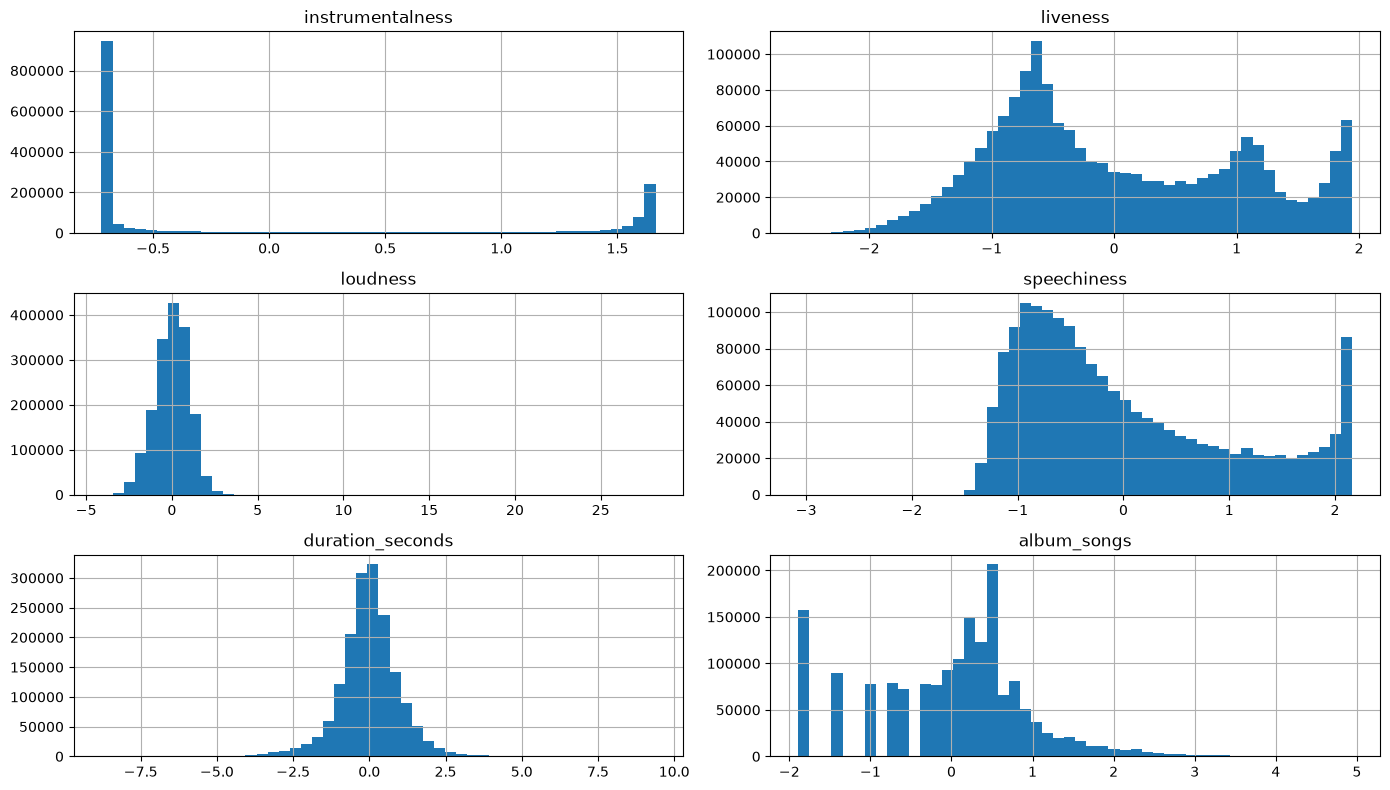

In [122]:
X_train_numeric_cat[skewed_features].hist(bins=50, figsize=(14, 8))

plt.tight_layout()
plt.show()

In [123]:
X_train_numeric_cat.skew(numeric_only=True)

instrumentalness      0.837662
liveness              0.365526
loudness              0.051703
speechiness           0.791418
duration_seconds      0.063618
album_songs           0.009105
acousticness          0.374148
danceability         -0.218924
energy               -0.325624
tempo                 0.359691
valence               0.046963
key_0                 2.325850
key_1                 3.068984
key_2                 2.433958
key_3                 5.289150
key_4                 3.062224
key_5                 2.970037
key_6                 3.823170
key_7                 2.229553
key_8                 3.877729
key_9                 2.504168
key_10                3.553005
key_11                3.329932
time_signature_0    183.849993
time_signature_1      9.028693
time_signature_3      2.485167
time_signature_4     -2.052095
time_signature_5      6.932422
dtype: float64

As shown in the histograms and skewness values above, our power transformation helped reduce the skewness of several numerical features. Standardization also centered the features around a mean of zero and scaled them to a standard deviation of one. These preprocessing steps make the features more suitable for PCA, which analyzes variation around the mean and can be influenced by differences in feature scales.

In [36]:
pca = PCA().set_output(transform='pandas')

In [37]:
X_train_pca = pca.fit_transform(X_train_numeric_cat)
X_validation_pca = pca.transform(X_validation_numeric_cat)
X_test_pca = pca.transform(X_test_numeric_cat)

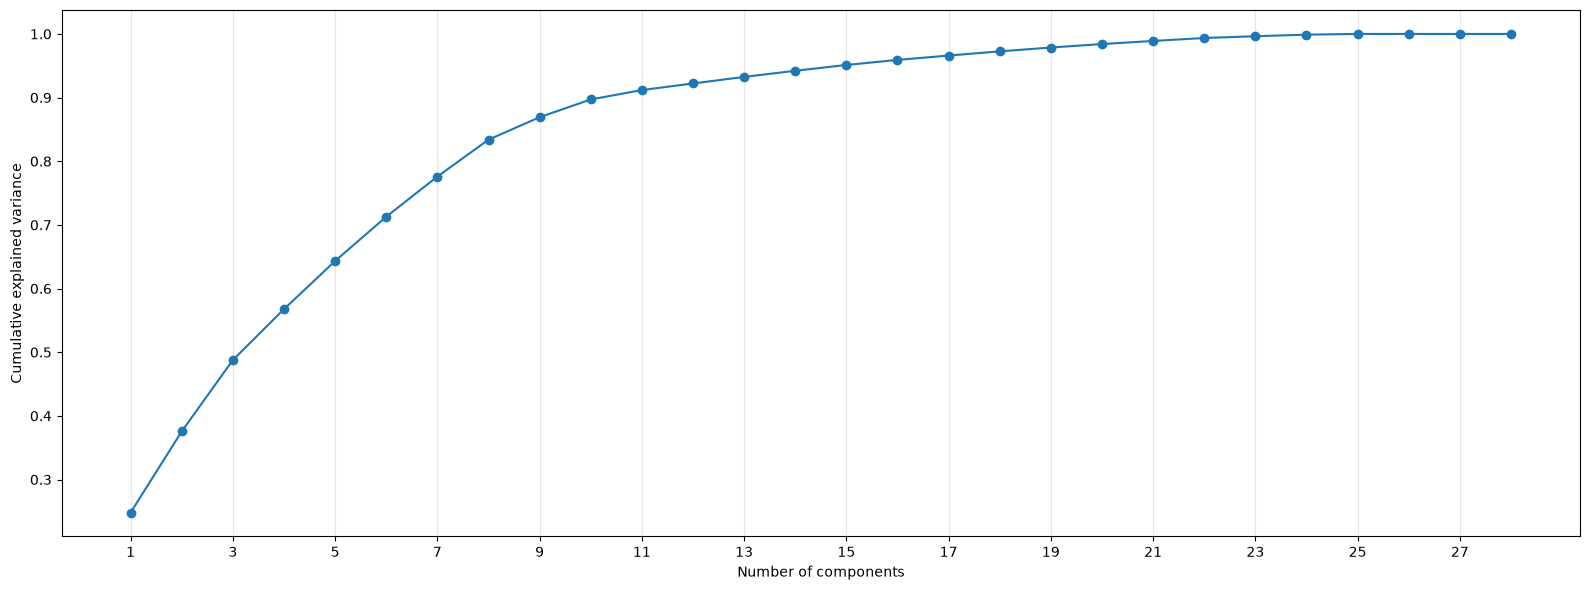

In [41]:
plt.figure(figsize=(16, 6))

explained_variance = np.cumsum(pca.explained_variance_ratio_)

plt.plot(range(1, len(explained_variance) + 1), explained_variance, marker='o')

plt.xticks(range(1, len(explained_variance) + 1, 2))
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [86]:
pca = PCA(n_components=13).set_output(transform='pandas')

In [87]:
X_train_pca = pca.fit_transform(X_train_numeric_cat)
X_validation_pca = pca.transform(X_validation_numeric_cat)
X_test_pca = pca.transform(X_test_numeric_cat)

In [97]:
print(f'Variance: {100 * np.cumsum(pca.explained_variance_ratio_)[-1]:.2f}%')
print(f'Number of features: {X_train_pca.shape[1]}')

Variance: 93.25%
Number of features: 13


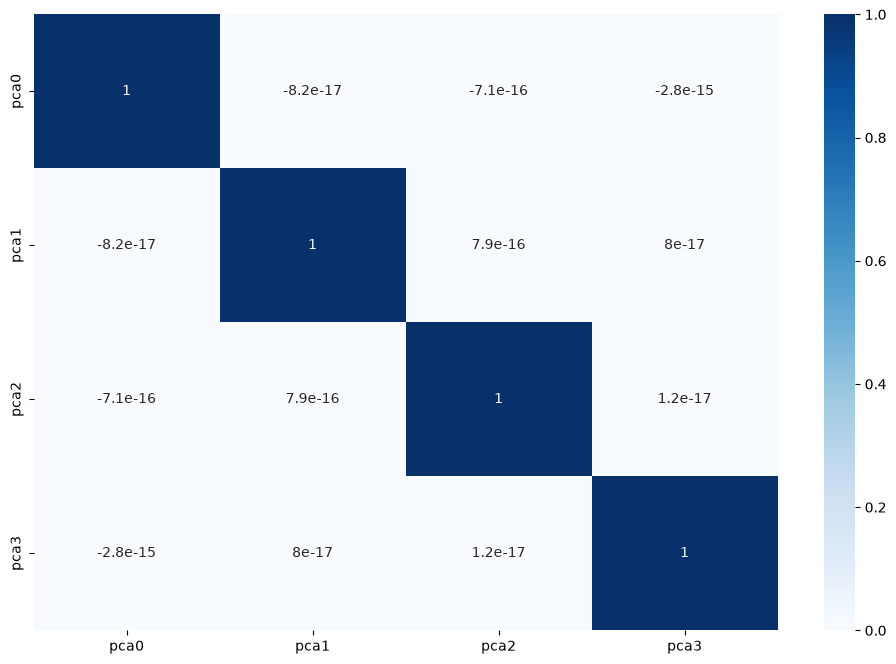

In [43]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    X_train_pca[['pca0', 'pca1', 'pca2', 'pca3']].corr(),
    annot=True,
    cmap='Blues'
)

plt.show()

The correlation matrix shows that the principal components are approximately **uncorrelated**, with correlations close to zero. This is an expected result of **PCA**, which transforms the original features into new, orthogonal components. This means the components capture different directions of variation in the data, with minimal linear correlation between them.

However, this PCA was performed only on our non-sparse audio features. Standard PCA is not suitable for our combined sparse dataset, which also includes TF-IDF text features. To reduce the dimensionality of this sparse data efficiently, we can use **TruncatedSVD** instead.

In [41]:
svd = TruncatedSVD(n_components=128, random_state=42)

In [42]:
X_train_svd = svd.fit_transform(X_train_transformed)
X_validation_svd = svd.transform(X_validation_transformed)
X_test_svd = svd.transform(X_test_transformed)

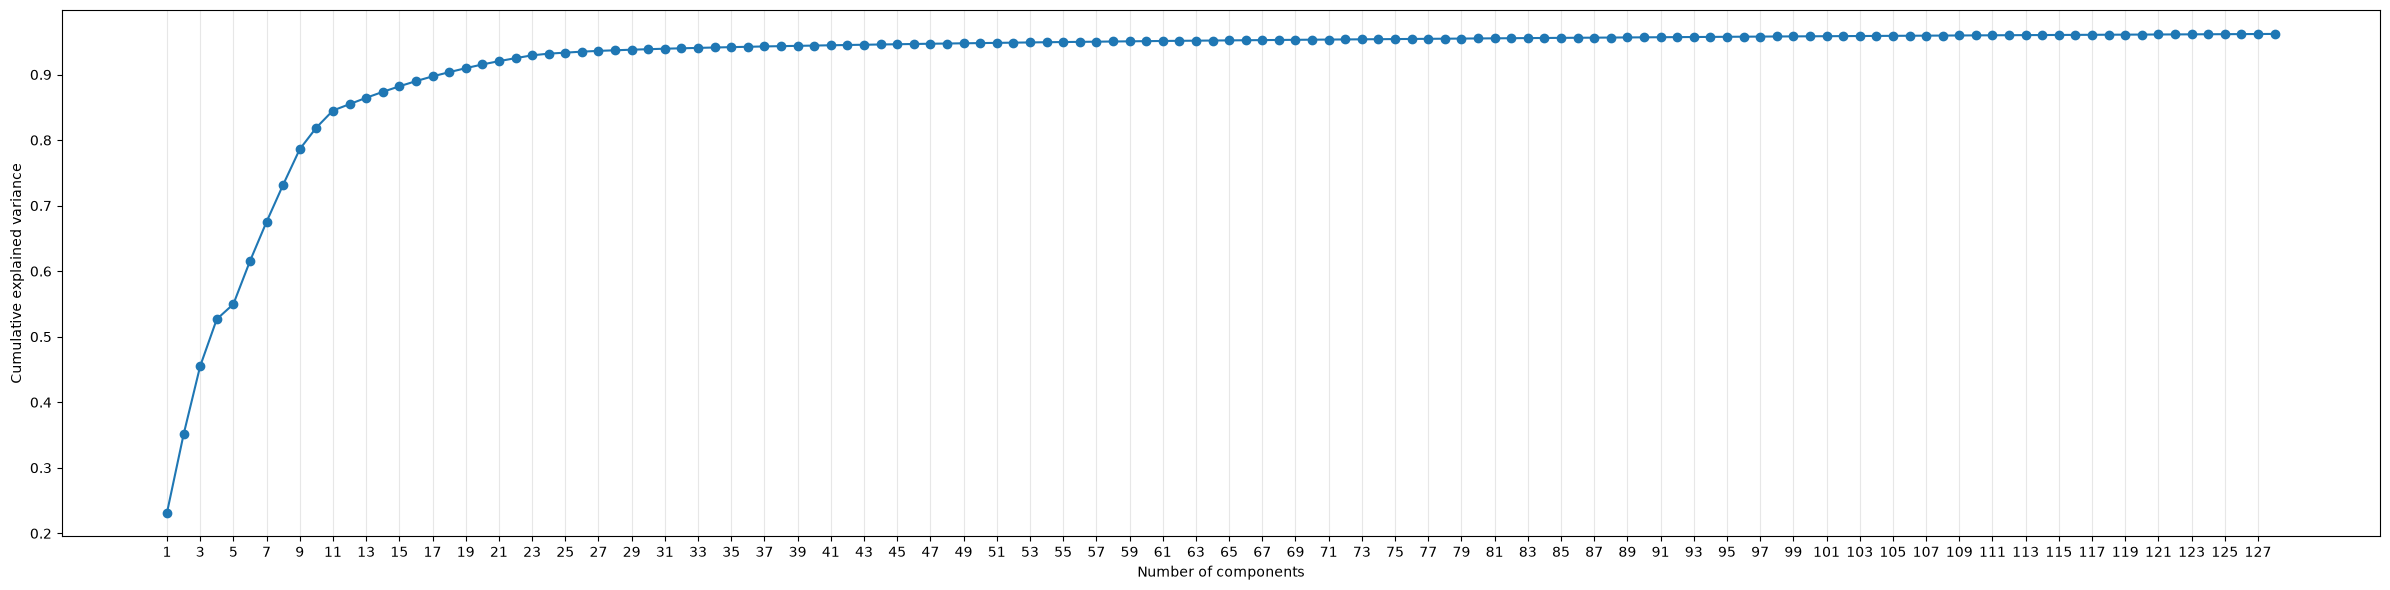

In [47]:
plt.figure(figsize=(24, 6))

explained_variance = np.cumsum(svd.explained_variance_ratio_)

plt.plot(range(1, len(explained_variance) + 1), explained_variance, marker='o')

plt.xticks(range(1, len(explained_variance) + 1, 2))
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [78]:
svd = TruncatedSVD(n_components=23, random_state=42)

In [79]:
X_train_svd = svd.fit_transform(X_train_transformed)
X_validation_svd = svd.transform(X_validation_transformed)
X_test_svd = svd.transform(X_test_transformed)

In [98]:
print(f'Variance: {100 * np.cumsum(svd.explained_variance_ratio_)[-1]:.2f}%')
print(f'Number of features: {X_train_svd.shape[1]}')

Variance: 92.93%
Number of features: 23


By reducing our feature space from **1,028** features to just **23** components using TruncatedSVD, we retain approximately **93%** of the explained variance. This substantially reduces the dimensionality of our data, helping mitigate the curse of dimensionality and making further analysis and modelling more computationally efficient.

In [142]:
svd_columns = [f"svd{i+1}" for i in range(X_train_svd.shape[1])]

sample_df = pd.DataFrame(
    X_train_svd,
    columns=svd_columns
)

sample_df['genre'] = np.asarray(y_train)

In [143]:
sample_df = (
    sample_df.groupby("genre", group_keys=False)
    .sample(n=50, random_state=42)
    .reset_index(drop=True)
)

X_sample = sample_df[svd_columns]
y_sample = sample_df["genre"]

We took 50 samples per `genre` class, to visualize our data in 2D, with our most important first and second SVD component on our plot. 

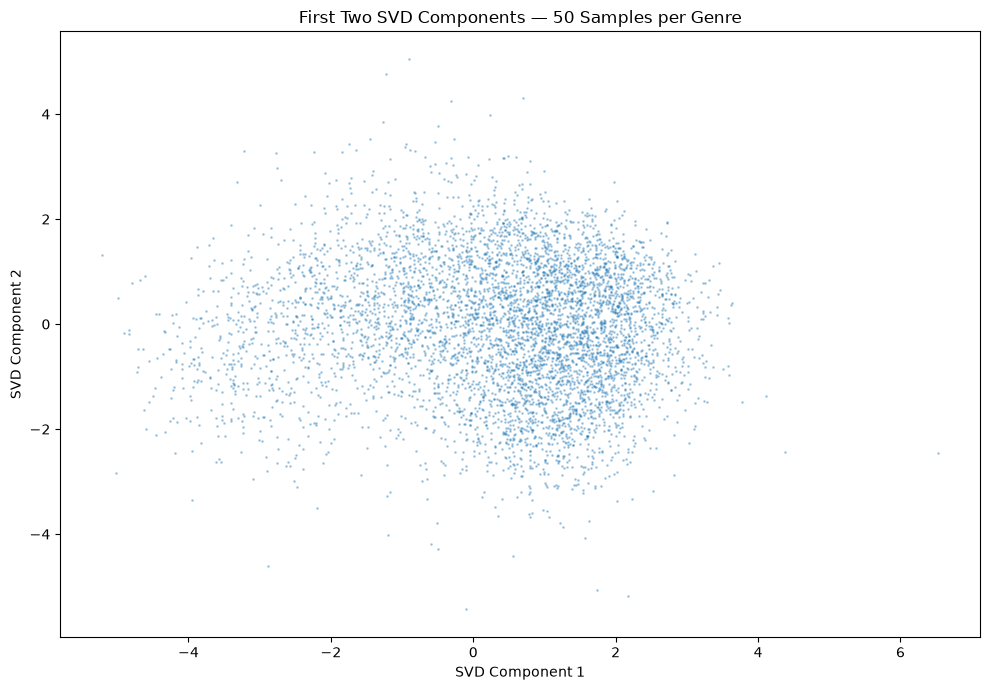

In [58]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X_sample['svd1'],
    X_sample['svd2'],
    s=1,
    alpha=0.3
)

plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.title("First Two SVD Components — 50 Samples per Genre")
plt.tight_layout()
plt.show()

### 1.2.6 Clustering

We observed a substantial class imbalance in our genre labels: the smallest genre contains only 66 tracks, while the largest contains 48,143. This imbalance can make genre classification more challenging, as models may perform better on well-represented genres than on underrepresented ones.

Next, we use **clustering** to identify groups of similar tracks and examine their genre distributions. This helps us explore whether similar genres could be combined into broader categories.

In [93]:
svd_columns = [f"svd{i+1}" for i in range(X_train_svd.shape[1])]

genre_means = pd.DataFrame(
    X_train_svd,
    columns=svd_columns
).groupby(np.asarray(y_train)).mean()

#### K-Means Clustering:

In [109]:
sse = []

for k in range(1, len(genre_means) + 1):
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(genre_means[['svd1', 'svd2', 'svd3', 'svd4']])
    sse.append(kmeans.inertia_)

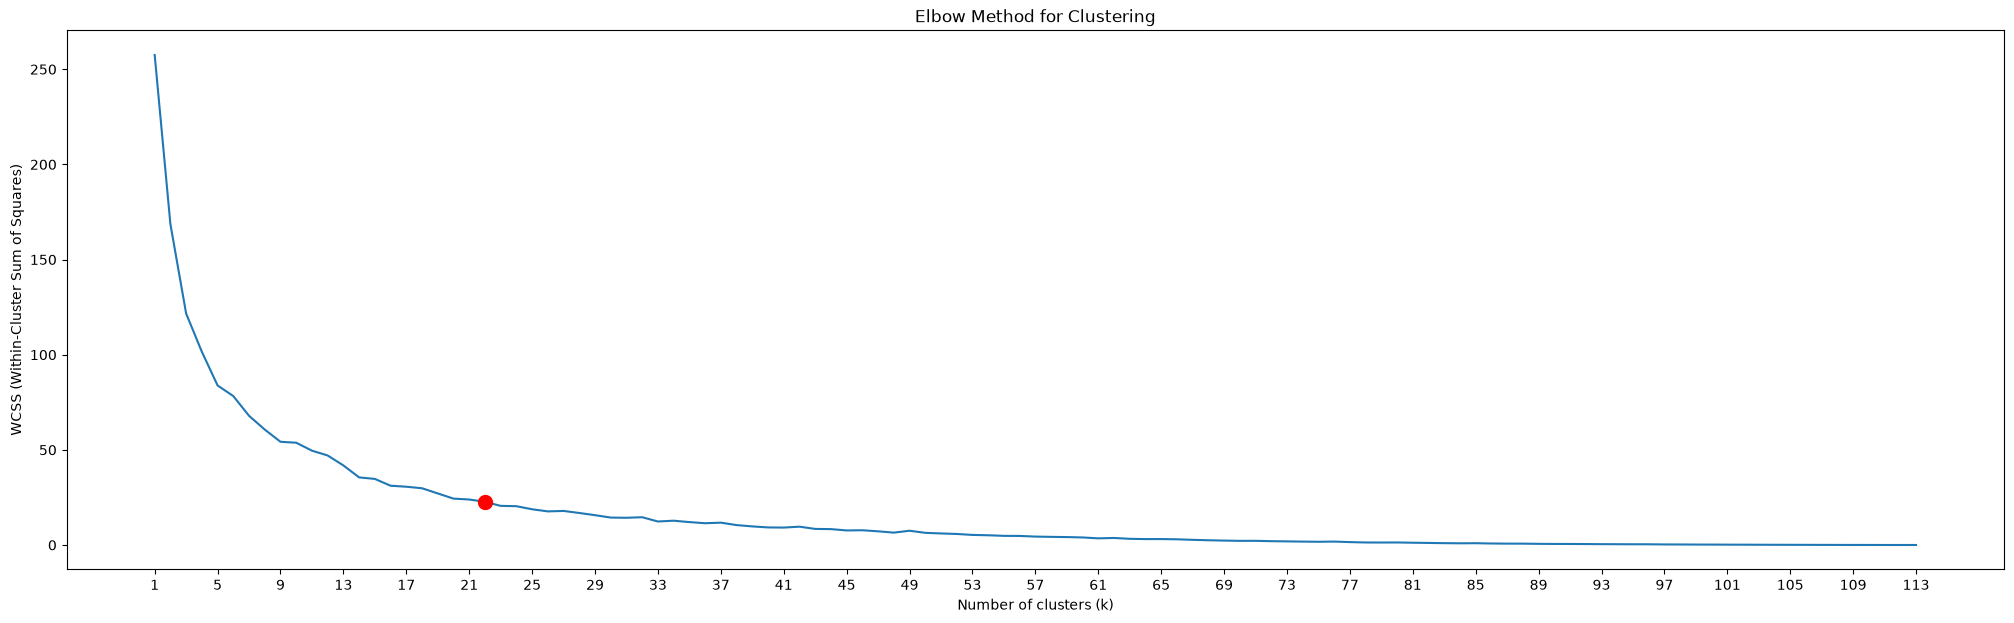

In [114]:
plt.figure(figsize=(25, 7))
plt.plot(range(1, len(genre_means) + 1), sse)

plt.scatter(22, sse[22 - 1], color='red', s=100, zorder=5)

plt.title('Elbow Method for Clustering')
plt.xlabel('Number of clusters (k)')
plt.ylabel('WCSS (Within-Cluster Sum of Squares)')
plt.xticks(range(1, len(genre_means) + 1, 4))

plt.show()

In [111]:
silhouette_scores = []

for k in range(2, len(genre_means)):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(genre_means[['svd1', 'svd2', 'svd3', 'svd4']])

    score = silhouette_score(
        genre_means[['svd1', 'svd2', 'svd3']],
        labels
    )
    silhouette_scores.append(score)

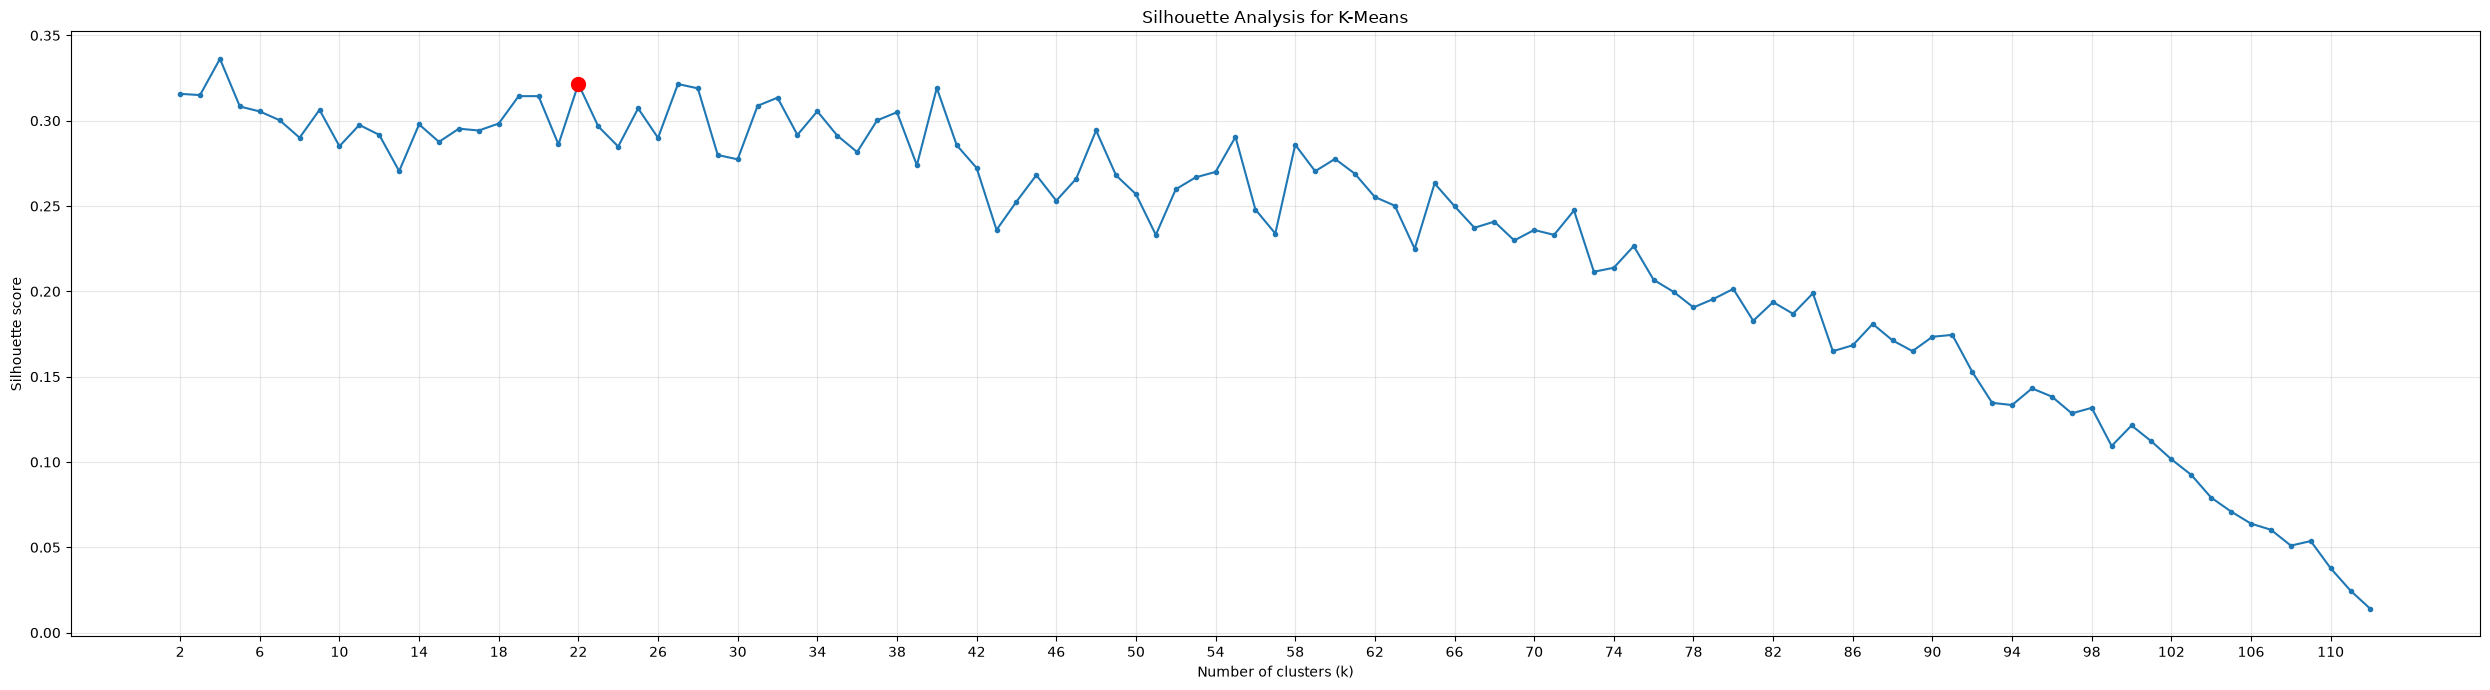

In [113]:
k_values = range(2, len(genre_means))

plt.figure(figsize=(25, 7))
plt.plot(k_values, silhouette_scores, marker='o', markersize=3)

plt.scatter(22, silhouette_scores[22 - 2], color='red', s=100, zorder=5)

plt.title('Silhouette Analysis for K-Means')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette score')

plt.xticks(range(2, len(genre_means), 4))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [115]:
km = KMeans(n_clusters=22, random_state=42, n_init=10)

In [116]:
genre_means['cluster'] = km.fit_predict(
    genre_means
)

In [117]:
genre_means.head()

,svd1,svd2,svd3,svd4,svd5,svd6,svd7,svd8,svd9,svd10,svd11,svd12,svd13,svd14,svd15,svd16,svd17,svd18,svd19,svd20,svd21,svd22,svd23,cluster
0,-0.805409,0.493689,-0.242742,0.044210,-0.239942,0.198746,-0.145135,0.019510,0.064730,0.185323,-0.068562,0.125964,-0.012342,0.025227,0.047669,0.004395,-0.017095,-0.012516,0.006785,0.010542,-0.000127,-0.006500,-0.023330,11
1,0.784856,0.181748,-0.662196,-0.005864,0.325136,-0.158296,0.553240,0.063794,-0.282309,-0.039192,-0.029923,0.085602,-0.010478,0.043223,0.012535,0.005982,-0.007423,-0.006693,0.003871,0.004987,0.007883,0.012407,-0.011360,13
2,0.677597,-0.283161,0.331524,0.264399,-0.432143,-0.302090,-0.068796,0.090165,0.076212,-0.189594,-0.008014,0.106596,0.008471,0.036323,0.019123,0.007431,-0.017307,-0.008733,-0.003003,0.001237,0.008221,0.003589,-0.018548,8
3,0.972665,-0.000966,0.262756,-0.230739,0.287496,-0.198818,-0.351870,0.267808,0.155656,0.010334,-0.103929,0.107065,0.001808,0.021564,0.012140,0.015748,-0.023267,-0.008147,-0.000599,0.000801,0.012105,0.000676,-0.018381,6
4,-2.511484,-1.209242,-0.204182,0.102001,0.393891,-0.103471,0.158148,-0.062311,-0.077046,-0.120632,0.014446,0.097324,0.021231,0.029447,0.003546,0.005948,-0.013900,0.000781,0.010176,-0.003603,-0.003272,0.002731,-0.009442,7


In [118]:
for cluster in sorted(genre_means['cluster'].unique()):
    encoded_genres = genre_means.index[
        genre_means['cluster'] == cluster
    ].to_numpy(dtype=int)

    genres = le.inverse_transform(encoded_genres)

    print(f"Cluster {cluster + 1}: [{', '.join(genres)}]")

Cluster 1: [bluegrass, honky-tonk, r-n-b, rock-n-roll, samba]
Cluster 2: [idm, iranian]
Cluster 3: [blues, brazil, country, indie, indie-pop, j-pop, j-rock, k-pop, latin, malay, psych-rock, rock, spanish, swedish]
Cluster 4: [british, disney, french, german, romance, show-tunes, tango]
Cluster 5: [drum-and-bass, happy, hardstyle]
Cluster 6: [chicago-house, deep-house, detroit-techno, house, minimal-techno]
Cluster 7: [alternative, sad]
Cluster 8: [ambient, classical, new-age, opera, sleep]
Cluster 9: [alt-rock, anime, emo, garage, goth, power-pop, punk, punk-rock, ska]
Cluster 10: [grindcore]
Cluster 11: [grunge, hard-rock, hardcore, heavy-metal, metal, metalcore]
Cluster 12: [acoustic, cantopop, folk, gospel, indian, mandopop, mpb, pop, pop-film, singer-songwriter, songwriter, soul, turkish, world-music]
Cluster 13: [comedy]
Cluster 14: [afrobeat, dance, disco, funk, j-dance, reggae, synth-pop]
Cluster 15: [dancehall, hip-hop, latino, reggaeton]
Cluster 16: [black-metal, death-metal]


In [ ]:
genre_to_cluster = genre_means['cluster'].to_dict()

In [125]:
y_train_cluster = pd.Series(y_train).map(genre_to_cluster).to_numpy()
y_test_cluster = pd.Series(y_test).map(genre_to_cluster).to_numpy()

In [126]:
def evaluate_model(model, X, y):
    y_pred = model.predict(X)

    accuracy = accuracy_score(y, y_pred)
    macro_f1 = f1_score(y, y_pred, average="macro")

    print(f"Accuracy: {accuracy:.2f}")
    print(f"Macro-F1: {macro_f1:.4f}")

In [122]:
rf = RandomForestClassifier(random_state=42)

In [ ]:
rf.fit(X_train_svd, y_train_cluster)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [127]:
evaluate_model(rf, X_test_svd, y_test_cluster)

Accuracy: 0.41
Macro-F1: 0.3914


In [ ]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_svd, y_train_cluster)

evaluate_model(dummy, X_test_svd, y_test_cluster)

Accuracy: 0.16
Macro-F1: 0.0122


Our baseline classifier got an accuracy of 0.16 , while our Decision Trees model got an accuracy of 0.41. Our model is thus less sensitive to the class imbalance, and actually generalizing following the data, using K-Means clustering method.

#### Hierachical Clustering:

In [133]:
linkage_data = linkage(
    genre_means[['svd1', 'svd2', 'svd3', 'svd4']],
    method="ward",
    metric="euclidean"
)

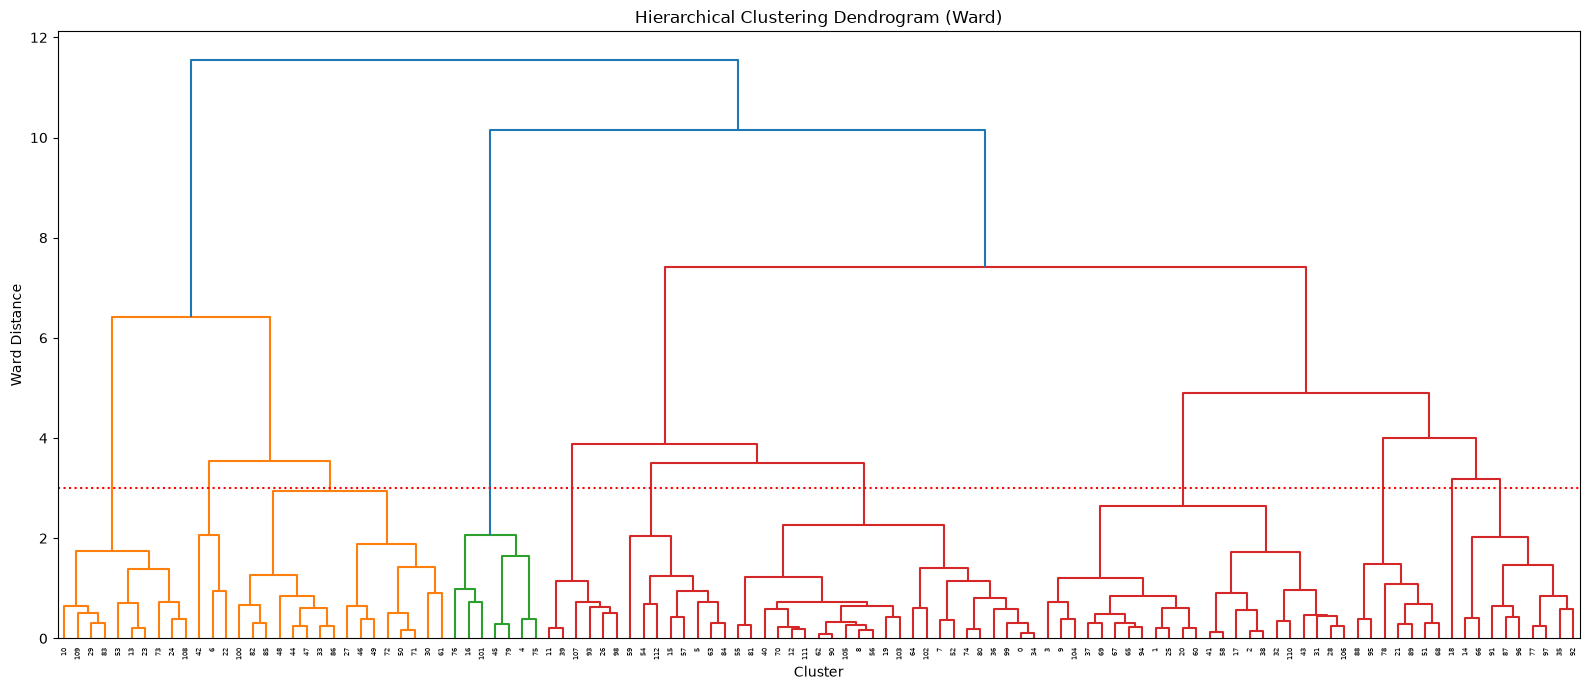

In [136]:
plt.figure(figsize=(16, 7))

dendrogram(linkage_data)

plt.axhline(y=3, color='red', linestyle=':', linewidth=1.5)

plt.title("Hierarchical Clustering Dendrogram (Ward)")
plt.xlabel("Cluster")
plt.ylabel("Ward Distance")
plt.tight_layout()
plt.show()

In [137]:
hierarchical_cluster = AgglomerativeClustering(n_clusters=11, linkage='ward')

In [138]:
hierarchical_labels = hierarchical_cluster.fit_predict(genre_means)

In [139]:
genre_means["hierarchical_cluster"] = hierarchical_labels

In [140]:
for cluster in sorted(genre_means['hierarchical_cluster'].unique()):
    encoded_genres = genre_means.index[
        genre_means['hierarchical_cluster'] == cluster
    ].to_numpy(dtype=int)

    genres = le.inverse_transform(encoded_genres)

    print(f"Cluster {cluster + 1}: [{', '.join(genres)}]")

Cluster 1: [bluegrass, blues, brazil, country, honky-tonk, idm, indie, indie-pop, iranian, j-pop, j-rock, k-pop, latin, malay, psych-rock, r-n-b, rock, rock-n-roll, samba, spanish, swedish]
Cluster 2: [alternative, chicago-house, deep-house, detroit-techno, drum-and-bass, happy, hardstyle, house, minimal-techno, sad]
Cluster 3: [children, chill, club, dub, edm, electro, electronic, groove, guitar, industrial, jazz, kids, piano, trip-hop]
Cluster 4: [acoustic, cantopop, comedy, folk, gospel, indian, mandopop, mpb, pop, pop-film, singer-songwriter, songwriter, soul, turkish, world-music]
Cluster 5: [grindcore, grunge, hard-rock, hardcore, heavy-metal, metal, metalcore]
Cluster 6: [black-metal, breakbeat, death-metal, dubstep, progressive-house, techno, trance]
Cluster 7: [ambient, classical, new-age, opera, sleep]
Cluster 8: [afrobeat, dance, dancehall, disco, funk, hip-hop, j-dance, latino, reggae, reggaeton, synth-pop]
Cluster 9: [forro, j-idol, pagode, party, rockabilly, salsa, sertan

ValueError: 'c' argument has 113 elements, which is inconsistent with 'x' and 'y' with size 5650.

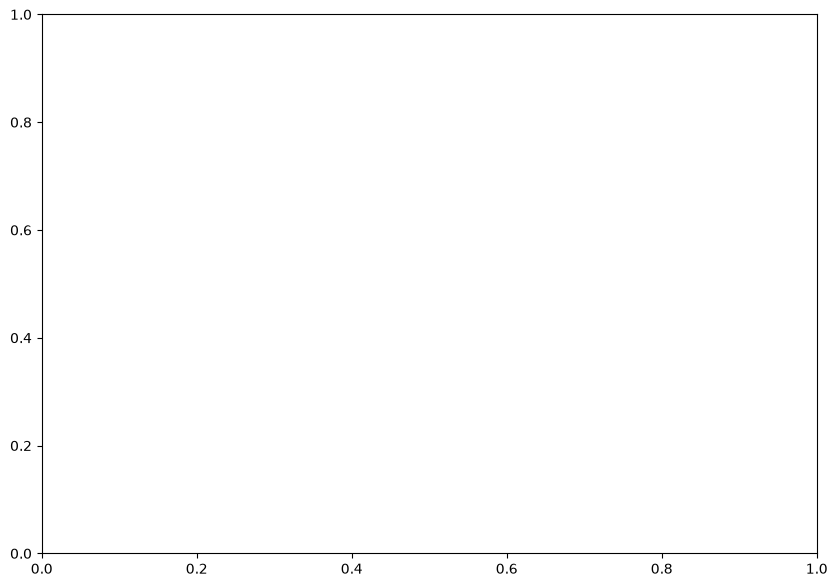

In [144]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_sample["svd1"],
    X_sample["svd2"],
    c=genre_means["hierarchical_cluster"],
    cmap="tab10",
    s=8,
    alpha=0.6
)

plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.title("Hierarchical Clustering — 7 Clusters (50 Samples per Genre)")

plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

In [71]:
sample_df["genre_name"] = le.inverse_transform(
    sample_df["genre"].astype(int)
)

In [72]:
pd.crosstab(
    sample_df["hierarchical_cluster"],
    sample_df["genre_name"]
)

genre_name,acoustic,afrobeat,alt-rock,alternative,ambient,anime,black-metal,bluegrass,blues,brazil,breakbeat,british,cantopop,chicago-house,children,chill,classical,club,comedy,country,dance,dancehall,death-metal,deep-house,detroit-techno,disco,disney,drum-and-bass,dub,dubstep,edm,electro,electronic,emo,folk,forro,french,funk,garage,german,gospel,goth,grindcore,groove,grunge,guitar,happy,hard-rock,hardcore,hardstyle,heavy-metal,hip-hop,honky-tonk,house,idm,indian,indie,indie-pop,industrial,iranian,j-dance,j-idol,j-pop,j-rock,jazz,k-pop,kids,latin,latino,malay,mandopop,metal,metalcore,minimal-techno,mpb,new-age,opera,pagode,party,piano,pop,pop-film,power-pop,progressive-house,psych-rock,punk,punk-rock,r-n-b,reggae,reggaeton,rock,rock-n-roll,rockabilly,romance,sad,salsa,samba,sertanejo,show-tunes,singer-songwriter,ska,sleep,songwriter,soul,spanish,swedish,synth-pop,tango,techno,trance,trip-hop,turkish,world-music
hierarchical_cluster,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,21,6,8,4,7,15,2,26,12,8,0,17,15,0,23,12,19,7,44,13,5,4,0,0,1,7,25,0,4,0,4,2,2,3,24,2,14,3,6,23,23,1,1,4,3,12,0,5,3,0,1,0,29,0,4,10,17,7,3,8,6,0,16,10,14,14,13,9,3,9,9,0,0,0,19,3,37,4,0,14,21,19,4,1,12,0,4,10,6,1,19,23,5,38,7,10,19,15,31,19,1,19,10,12,7,9,2,33,1,1,8,19,5
1,3,1,10,12,1,8,10,0,6,11,9,0,4,2,7,1,1,9,2,8,4,8,27,1,3,3,5,9,9,4,10,5,4,21,1,11,2,8,9,7,4,6,36,13,18,1,18,10,26,23,24,8,5,4,6,7,6,11,11,7,8,20,6,9,1,8,4,6,14,9,3,24,29,2,1,1,1,8,19,2,5,4,13,8,8,24,19,7,8,11,6,4,9,2,8,5,2,5,3,0,20,0,3,3,9,11,0,1,1,5,4,9,5
2,5,20,11,10,18,11,33,4,6,6,30,7,1,33,2,19,0,26,0,1,8,0,20,34,44,9,2,39,26,34,30,20,31,2,3,3,4,11,18,3,0,15,10,17,3,8,30,10,7,19,7,1,2,31,30,6,7,6,21,15,12,11,2,7,12,1,7,1,7,1,0,9,14,45,2,5,0,0,0,3,3,1,7,37,11,7,8,0,5,0,2,2,4,1,0,3,2,0,0,2,3,1,4,4,4,5,12,2,41,40,22,2,6
3,16,10,8,6,2,6,1,8,13,9,3,1,19,8,3,10,0,6,1,17,13,4,0,2,0,15,6,1,1,2,1,11,4,9,13,9,9,7,6,5,12,13,0,6,13,6,1,7,3,5,8,5,4,8,3,15,12,13,7,1,10,10,13,8,10,20,6,18,7,21,28,8,3,1,12,1,3,11,7,2,11,17,7,0,7,6,7,14,11,11,12,8,12,5,17,18,8,13,5,21,10,0,21,13,7,15,16,5,3,3,7,4,17
4,3,0,0,0,21,5,3,5,2,0,0,18,0,0,0,4,29,0,0,0,0,0,1,0,0,0,6,0,2,0,0,2,1,0,5,0,9,3,1,8,0,1,0,2,1,19,0,1,0,0,0,0,1,0,6,4,1,2,0,17,0,0,0,2,10,0,2,2,0,1,0,0,0,0,3,39,9,0,0,22,3,2,1,0,2,0,0,0,0,0,0,0,0,1,2,0,0,0,4,1,0,30,4,1,2,2,0,6,1,0,2,5,8
5,1,9,2,14,1,1,0,1,4,6,2,2,3,5,8,3,0,0,3,2,11,32,0,9,1,9,3,1,7,8,2,8,6,6,2,2,6,14,1,1,8,3,0,4,1,1,0,1,8,0,0,31,2,6,0,5,1,6,3,0,9,0,3,3,2,5,11,7,14,0,1,0,1,1,4,0,0,10,13,2,1,2,1,3,1,2,1,8,14,18,8,4,4,2,14,9,7,2,1,1,5,0,2,9,10,1,2,2,3,0,5,4,0
6,1,4,11,4,0,4,1,6,7,10,6,5,8,2,7,1,1,2,0,9,9,2,2,4,1,7,3,0,1,2,3,2,2,9,2,23,6,4,9,3,3,11,3,4,11,3,1,16,3,3,10,5,7,1,1,3,6,5,5,2,5,9,10,11,1,2,7,7,5,9,9,9,3,1,9,1,0,17,11,5,6,5,17,1,9,11,11,11,6,9,3,9,16,1,2,5,12,15,6,6,11,0,6,8,11,7,18,1,0,1,2,7,9


In [73]:
for cluster, group in sample_df.groupby("hierarchical_cluster"):
    genres = sorted(group["genre_name"].unique())
    print(f"Cluster {cluster + 1}: {genres}")

Cluster 1: ['acoustic', 'afrobeat', 'alt-rock', 'alternative', 'ambient', 'anime', 'black-metal', 'bluegrass', 'blues', 'brazil', 'british', 'cantopop', 'children', 'chill', 'classical', 'club', 'comedy', 'country', 'dance', 'dancehall', 'detroit-techno', 'disco', 'disney', 'dub', 'edm', 'electro', 'electronic', 'emo', 'folk', 'forro', 'french', 'funk', 'garage', 'german', 'gospel', 'goth', 'grindcore', 'groove', 'grunge', 'guitar', 'hard-rock', 'hardcore', 'heavy-metal', 'honky-tonk', 'idm', 'indian', 'indie', 'indie-pop', 'industrial', 'iranian', 'j-dance', 'j-pop', 'j-rock', 'jazz', 'k-pop', 'kids', 'latin', 'latino', 'malay', 'mandopop', 'mpb', 'new-age', 'opera', 'pagode', 'piano', 'pop', 'pop-film', 'power-pop', 'progressive-house', 'psych-rock', 'punk-rock', 'r-n-b', 'reggae', 'reggaeton', 'rock', 'rock-n-roll', 'rockabilly', 'romance', 'sad', 'salsa', 'samba', 'sertanejo', 'show-tunes', 'singer-songwriter', 'ska', 'sleep', 'songwriter', 'soul', 'spanish', 'swedish', 'synth-pop'

## 2.1 Model training

In [41]:
lr_model = LogisticRegression(
        solver="saga",
        max_iter=300
)

lr_model.fit(X_train_svd, y_train)

/home/thomas/projects/venv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'saga'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",300
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of t

In [74]:
cb_model = CatBoostClassifier(task_type='GPU', devices='0')

In [ ]:
xb_model = XGBClassifier(tree_method='hist', device='cuda')

In [76]:
cb_model.fit(X_train_svd, y_train, verbose=True)

Learning rate set to 0.295653
0:	learn: 4.3311714	total: 377ms	remaining: 6m 16s
1:	learn: 4.2985449	total: 751ms	remaining: 6m 14s
2:	learn: 16.6321413	total: 1.12s	remaining: 6m 13s
3:	learn: 17.2540043	total: 1.5s	remaining: 6m 12s
4:	learn: 17.1067747	total: 1.87s	remaining: 6m 12s
5:	learn: 17.6199011	total: 2.24s	remaining: 6m 11s
6:	learn: 16.0279356	total: 2.61s	remaining: 6m 10s
7:	learn: 15.8258962	total: 2.98s	remaining: 6m 9s
8:	learn: 13.7347034	total: 3.35s	remaining: 6m 9s
9:	learn: 13.6372484	total: 3.73s	remaining: 6m 9s
10:	learn: 12.5205801	total: 4.1s	remaining: 6m 9s
11:	learn: 10.7980672	total: 4.48s	remaining: 6m 8s
12:	learn: 10.5214380	total: 4.85s	remaining: 6m 8s
13:	learn: 10.4749825	total: 5.22s	remaining: 6m 7s
14:	learn: 10.4222720	total: 5.6s	remaining: 6m 7s
15:	learn: 10.3546660	total: 5.97s	remaining: 6m 7s
16:	learn: 10.3047399	total: 6.34s	remaining: 6m 6s
17:	learn: 10.2712368	total: 6.71s	remaining: 6m 6s
18:	learn: 10.2430279	total: 7.09s	remaini

CatBoostClassifier(devices='0', task_type='GPU')

## 2.2 Model optimization

In [77]:
from sklearn.metrics import f1_score

y_pred = cb_model.predict(X_test_svd)

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")

print(f"Model Accuracy: {accuracy:.2f}")
print(f"Test Macro-F1: {macro_f1:.4f}")

Model Accuracy: 0.20
Test Macro-F1: 0.1656
